# Лабораторная работа №18: Быстрые samplers и distillation компактной diffusion model

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Переиспользовать checkpoint lab 17.
- Сравнить DDPM, DDIM и дополнительный solver.
- Обучить compact student и построить Pareto frontier.

## Теоретическая часть

DDIM использует тот же denoiser, но может идти по сокращённой последовательности timesteps детерминированно. Distillation обучает student воспроизводить несколько teacher steps одним шагом. Сравнение строится при одинаковых initial noise и labels.


DDIM вычисляет x̂0 и делает детерминированный переход между точками ᾱ. DPM-Solver++ использует тот же обученный ε-предсказатель. Progressive distillation аппроксимирует двумя teacher-переходами один student-переход; teacher заморожен.

Детерминированный DDIM-переход: $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\hat\epsilon)/\sqrt{\bar\alpha_t}$, $x_s=\sqrt{\bar\alpha_s}\hat x_0+\sqrt{1-\bar\alpha_s}\hat\epsilon$. При конечном $s=-1$ полагаем $\bar\alpha_{-1}=1$.

### Экспериментальный протокол

Обязательная зависимость — реально обученные веса ddpm.pt, classifier.pt и classifier_validation.json из lab 17. Используйте те же классы, noise и guidance=3 при сравнении. Smoke не является подтверждением качества distillation. Для длинных запусков обеспечьте постоянный каталог artifacts (Drive).

### Материалы

- [DDIM](https://arxiv.org/abs/2010.02502)
- [Progressive Distillation](https://arxiv.org/abs/2202.00512)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time, math, copy, csv, hashlib
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
# Детерминированные свёртки: два запуска DDIM на одном шуме должны совпадать
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# У каждой лабы своя папка: artifacts/lab18 — метрики, PNG, checkpoint student; smoke — в artifacts/lab18/smoke.
# Teacher, classifier и их валидация читаются из результатов lab 17 (artifacts/lab17), там они не меняются.
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab18'))
if FAST_DEV_RUN:
    ARTIFACTS = ARTIFACTS / 'smoke'
LAB17 = Path(os.getenv('CV_LAB17', 'artifacts/lab17'))
LAB17_DATA = Path(os.getenv('CV_LAB17_DATA', 'data/lab17'))   # зафиксированный split lab 17
DATA_ROOT = Path(os.getenv('CV_DATA', 'data/lab18'))
MNIST_ROOT = Path(os.getenv('CV_MNIST', 'data'))               # общий MNIST уже лежит в data/MNIST/raw
CKPT_DIR = ARTIFACTS / 'checkpoints'
FIG_DIR = ARTIFACTS / 'figures'
PNG_DIR = ARTIFACTS / 'samples_png'
for folder in (ARTIFACTS, DATA_ROOT, CKPT_DIR, FIG_DIR, PNG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Протокол: teacher lab 17 (≥ 10 000 обновлений) + CFG w=3 для всех sampler;
# сокращённый режим — малые сетки шагов, 2 картинки на класс и 2 шага distillation (только связность)
MIN_TEACHER_STEPS = 10_000
GUIDANCE = 3.0
SAMPLES_PER_CLASS = 2 if FAST_DEV_RUN else 10
DDIM_STEPS = [5, 10, 20] if FAST_DEV_RUN else [5, 10, 20, 50, 100]
DPM_STEPS = [5, 10] if FAST_DEV_RUN else [5, 10, 20]
TEACHER_STEPS, STUDENT_STEPS = 20, 10          # один раунд progressive distillation: 2 шага teacher → 1 шаг student
N_TRAIN = 512 if FAST_DEV_RUN else 20_000      # те же первые картинки MNIST train, на которых учился teacher
N_DVAL = 64 if FAST_DEV_RUN else 512           # следующие картинки train — validation distillation (test не трогаем)
DISTILL_STEPS = 2 if FAST_DEV_RUN else 4000
DISTILL_BATCH = 16 if FAST_DEV_RUN else 128
RUN_TAG = 'smoke' if FAST_DEV_RUN else 'full'
NOTEBOOK_T0 = time.time()


def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding='utf-8')


def cuda_sync():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()


print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN, 'artifacts': str(ARTIFACTS), 'lab17': str(LAB17),
       'data': str(DATA_ROOT), 'mnist': str(MNIST_ROOT), 'guidance': GUIDANCE,
       'samples_per_class': SAMPLES_PER_CLASS, 'ddim_steps': DDIM_STEPS, 'dpm_steps': DPM_STEPS,
       'teacher/student steps': (TEACHER_STEPS, STUDENT_STEPS), 'distill_steps': DISTILL_STEPS})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts\\lab18', 'lab17': 'artifacts\\lab17', 'data': 'data\\lab18', 'mnist': 'data', 'guidance': 3.0, 'samples_per_class': 10, 'ddim_steps': [5, 10, 20, 50, 100], 'dpm_steps': [5, 10, 20], 'teacher/student steps': (20, 10), 'distill_steps': 4000}


### Задание 1. Проверка обученного teacher

*Вес: 1 балл.*

**Постановка.** Сравнение sampler допустимо лишь при одинаковой обученной модели, классах и исходном шуме. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите checkpoint lab 17, запретите случайную замену и проверьте совместимость шагов/T.

**Результат.** Проверяемое состояние «Проверка обученного teacher» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите checkpoint lab 17, запретите случайную замену и проверьте совместимость шагов/T» и его результат доступен следующему этапу.

**Проверка обученного teacher**

- **Что делали**: загрузили `ddpm.pt` из lab 17 без запасного варианта: если файла нет, ячейка падает, случайная модель не подставляется. Проверили режим и число шагов обучения, пересчитали beta-расписание и сверили T и границы beta с checkpoint и `schedule.json`. Загрузили веса строго (strict) и проверили, что они отличаются от случайной инициализации. На 256 картинках MNIST test измерили, насколько точно teacher угадывает шум.
- **Зачем**: сравнивать sampler имеет смысл только на одной и той же реально обученной модели с тем же расписанием шагов; иначе разница в результатах объяснялась бы моделью, а не sampler.
- **Результат**: teacher_check.json. Режим full, 10 000 шагов обучения, T = 1000, ᾱ_T = 4.0e-5, 2.33 млн параметров, 100% тензоров отличаются от случайных. Ошибка предсказания шума (условная / безусловная): 0.055 / 0.055 при t = 100, 0.0107 / 0.0133 при t = 500, 0.00009 / 0.0001 при t = 900, тогда как тривиальный ответ ε̂ = 0 даёт 0.996. Все проверки ✔.

In [2]:
# Задание 1. Проверка обученного teacher
from torchvision import datasets

# --- Архитектуры и расписание — точные копии lab 17, иначе state_dict teacher/classifier не загрузится ---
BETA_START, BETA_END = 1e-4, 0.02


def diffusion_schedule(T, beta_start=BETA_START, beta_end=BETA_END):
    """Линейный beta-schedule lab 17 (границы растянуты в 1000/T раз). Хранится в float64:
    коэффициенты sampler при ᾱ_T ≈ 4e-5 чувствительны к округлению."""
    scale = 1000 / T
    betas = torch.linspace(beta_start * scale, beta_end * scale, T, dtype=torch.float64)
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, 0)
    alpha_bars_prev = torch.cat([torch.ones(1, dtype=torch.float64), alpha_bars[:-1]])
    posterior_var = betas * (1 - alpha_bars_prev) / (1 - alpha_bars)  # beta_tilde_t
    return {'betas': betas, 'alphas': alphas, 'alpha_bars': alpha_bars,
            'alpha_bars_prev': alpha_bars_prev, 'posterior_var': posterior_var}


def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, emb_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.emb = nn.Linear(emb_dim, c_out)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.drop = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(F.silu(emb))[:, :, None, None]
        h = self.conv2(self.drop(F.silu(self.norm2(h))))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.attn = nn.MultiheadAttention(ch, heads, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        s = self.norm(x).flatten(2).transpose(1, 2)
        out, _ = self.attn(s, s, s, need_weights=False)
        return x + out.transpose(1, 2).reshape(b, c, h, w)


class TinyDenoiser(nn.Module):
    """Compact U-Net lab 17 28→14→7→14→28: предсказывает ε по (x_t, t, y); y=10 — безусловная ветвь CFG."""

    def __init__(self, base=64, mults=(1, 2, 2), num_classes=10, emb_dim=256, dropout=0.1):
        super().__init__()
        self.config = {'base': base, 'mults': list(mults), 'num_classes': num_classes,
                       'emb_dim': emb_dim, 'dropout': dropout}
        self.null_class = num_classes
        c1, c2, c3 = (base * m for m in mults)
        self.time_mlp = nn.Sequential(nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.class_emb = nn.Embedding(num_classes + 1, emb_dim)
        self.inp = nn.Conv2d(1, c1, 3, padding=1)
        self.down1 = ResBlock(c1, c1, emb_dim, dropout)
        self.ds1 = nn.Conv2d(c1, c1, 3, stride=2, padding=1)
        self.down2 = ResBlock(c1, c2, emb_dim, dropout)
        self.ds2 = nn.Conv2d(c2, c2, 3, stride=2, padding=1)
        self.mid1 = ResBlock(c2, c3, emb_dim, dropout)
        self.attn = SelfAttention(c3)
        self.mid2 = ResBlock(c3, c3, emb_dim, dropout)
        self.us2 = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(c3, c3, 3, padding=1))
        self.up2 = ResBlock(c3 + c2, c2, emb_dim, dropout)
        self.us1 = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(c2, c2, 3, padding=1))
        self.up1 = ResBlock(c2 + c1, c1, emb_dim, dropout)
        self.out = nn.Sequential(nn.GroupNorm(8, c1), nn.SiLU(), nn.Conv2d(c1, 1, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight)
        nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, y):
        emb = self.time_mlp(timestep_embedding(t, self.config['base'])) + self.class_emb(y)
        h1 = self.down1(self.inp(x), emb)
        h2 = self.down2(self.ds1(h1), emb)
        h = self.mid2(self.attn(self.mid1(self.ds2(h2), emb)), emb)
        h = self.up2(torch.cat([self.us2(h), h2], 1), emb)
        h = self.up1(torch.cat([self.us1(h), h1], 1), emb)
        return self.out(h)


class DigitClassifier(nn.Module):
    """Проверяющий CNN lab 17, вход в шкале [-1, 1]."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 49, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def to_model_range(u8):
    """uint8 → [-1, 1], как при обучении lab 17."""
    return u8.unsqueeze(1).float() / 127.5 - 1.0


# --- Обязательные артефакты lab 17: никакой подмены случайной инициализацией ---
TEACHER_PATH = LAB17 / 'ddpm.pt'
CLASSIFIER_PATH = LAB17 / 'classifier.pt'
CLS_JSON_PATH = LAB17 / 'classifier_validation.json'
missing = [str(p) for p in (TEACHER_PATH, CLASSIFIER_PATH, CLS_JSON_PATH) if not p.exists()]
if missing:
    raise FileNotFoundError(f'нет артефактов lab 17: {missing}. Выполните student_17.ipynb в полном режиме; '
                            'случайно инициализированный teacher не допускается')

TEACHER_SHA = file_sha256(TEACHER_PATH)
ck = torch.load(TEACHER_PATH, map_location='cpu', weights_only=False)
assert ck['weights'] == 'ema', 'для сэмплирования нужны EMA-веса'
if not FAST_DEV_RUN:
    assert ck['run_tag'] == 'full', f"teacher из режима {ck['run_tag']}: smoke checkpoint не годится для оценки"
    assert ck['step'] >= MIN_TEACHER_STEPS, f"teacher обучен {ck['step']} < {MIN_TEACHER_STEPS} обновлений"

# --- Совместимость шагов: T и границы beta из checkpoint ↔ пересчитанное расписание ---
T_STEPS = int(ck['schedule']['T'])
SCHED = diffusion_schedule(T_STEPS)
AB = SCHED['alpha_bars']  # float64, индекс t = 0..T−1
assert ck['schedule']['type'].startswith('linear'), ck['schedule']
assert math.isclose(ck['schedule']['beta_start'], BETA_START * 1000 / T_STEPS, rel_tol=1e-6)
assert math.isclose(ck['schedule']['beta_end'], BETA_END * 1000 / T_STEPS, rel_tol=1e-6)
assert math.isclose(SCHED['betas'][0].item(), ck['schedule']['beta_start'], rel_tol=1e-6)
assert math.isclose(SCHED['betas'][-1].item(), ck['schedule']['beta_end'], rel_tol=1e-6)
assert bool((AB[1:] < AB[:-1]).all()) and len(AB) == T_STEPS
schedule17 = LAB17 / 'schedule.json'
ab_T_lab17 = None
if schedule17.exists():
    s17 = json.loads(schedule17.read_text(encoding='utf-8'))
    if s17['T'] == T_STEPS:
        ab_T_lab17 = s17['alpha_bar_T']
        assert math.isclose(AB[-1].item(), ab_T_lab17, rel_tol=1e-4), (AB[-1].item(), ab_T_lab17)

# --- Загрузка весов: strict, без пропущенных/лишних ключей; веса должны отличаться от инициализации ---
NULL_CLASS = int(ck['null_class'])
teacher = TinyDenoiser(**ck['model_config'])
init_state = {k: v.clone() for k, v in teacher.state_dict().items()}
teacher.load_state_dict(ck['model'], strict=True)
teacher = teacher.to(DEVICE).eval().requires_grad_(False)
assert teacher.null_class == NULL_CLASS
float_keys = [k for k, v in init_state.items() if v.is_floating_point()]
changed = [k for k in float_keys if not torch.equal(teacher.state_dict()[k].cpu(), init_state[k])]
changed_frac = len(changed) / len(float_keys)
assert changed_frac > 0.9, f'только {changed_frac:.2f} тензоров отличаются от случайной инициализации'
del init_state
n_params = sum(p.numel() for p in teacher.parameters())

# --- Функциональная проверка на real MNIST test: обученный ε̂ намного лучше тривиального ε̂ = 0 ---
mnist_test = datasets.MNIST(MNIST_ROOT, train=False, download=False)
probe_x0 = to_model_range(mnist_test.data[:256]).to(DEVICE)
probe_y = mnist_test.targets[:256].to(DEVICE)
probe_noise = torch.randn(probe_x0.shape, generator=torch.Generator().manual_seed(SEED + 7)).to(DEVICE)
zero_pred_mse = probe_noise.pow(2).mean().item()
teacher_rows = []
with torch.no_grad():
    for t_val in sorted({T_STEPS // 10, T_STEPS // 2, 9 * T_STEPS // 10}):
        t = torch.full((len(probe_x0),), t_val, device=DEVICE, dtype=torch.long)
        ab = AB[t_val].item()
        xt = math.sqrt(ab) * probe_x0 + math.sqrt(1 - ab) * probe_noise
        teacher_rows.append({'t': t_val, 'alpha_bar': ab,
                             'cond_mse': (teacher(xt, t, probe_y) - probe_noise).pow(2).mean().item(),
                             'uncond_mse': (teacher(xt, t, torch.full_like(probe_y, NULL_CLASS)) - probe_noise).pow(2).mean().item()})
mid_row = next(r for r in teacher_rows if r['t'] == T_STEPS // 2)
assert mid_row['cond_mse'] < 0.5 * zero_pred_mse, 'teacher не лучше ε̂=0 — это не обученная модель'
if not FAST_DEV_RUN:
    assert mid_row['cond_mse'] < 0.25, mid_row

teacher_check = {'checkpoint': str(TEACHER_PATH), 'sha256': TEACHER_SHA, 'run_tag': ck['run_tag'],
                 'train_steps': ck['step'], 'min_required_steps': MIN_TEACHER_STEPS, 'weights': ck['weights'],
                 'model_config': ck['model_config'], 'n_params': n_params, 'schedule': ck['schedule'],
                 'T': T_STEPS, 'alpha_bar_T': AB[-1].item(), 'alpha_bar_T_lab17_json': ab_T_lab17,
                 'null_class': NULL_CLASS, 'strict_load': True,
                 'tensors_changed_from_random_init': changed_frac,
                 'noise_mse_real_test256': teacher_rows, 'zero_pred_mse': zero_pred_mse}
save_json('teacher_check.json', teacher_check)
print({k: teacher_check[k] for k in ['run_tag', 'train_steps', 'T', 'alpha_bar_T', 'n_params',
                                     'tensors_changed_from_random_init']}, TEACHER_SHA[:16])
for r in teacher_rows:
    print({k: round(v, 5) if isinstance(v, float) else v for k, v in r.items()})

{'run_tag': 'full', 'train_steps': 10000, 'T': 1000, 'alpha_bar_T': 4.0358297653756754e-05, 'n_params': 2329409, 'tensors_changed_from_random_init': 1.0} 99d651e3b72c990e
{'t': 100, 'alpha_bar': 0.89514, 'cond_mse': 0.05467, 'uncond_mse': 0.05486}
{'t': 500, 'alpha_bar': 0.0778, 'cond_mse': 0.01071, 'uncond_mse': 0.01334}
{'t': 900, 'alpha_bar': 0.00027, 'cond_mse': 9e-05, 'uncond_mse': 0.0001}


### Задание 2. Воспроизводимый протокол сравнения

*Вес: 1 балл.*

**Постановка.** Сравнение sampler допустимо лишь при одинаковой обученной модели, классах и исходном шуме. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте общие классы и шум, сохраните seed и качество классификатора.

**Результат.** Проверяемое состояние «Воспроизводимый протокол сравнения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте общие классы и шум, сохраните seed и качество классификатора» и его результат доступен следующему этапу.

**Общий протокол сравнения**

- **Что делали**: загрузили классификатор-судью из lab 17 и заново проверили его на тех же 2000 картинках MNIST test. Задали общие для всех sampler метки (по 10 картинок на каждую цифру), начальный шум x_T из seed 1842, отдельный seed 1843 для случайного шума DDPM и guidance w = 3. Написали `guided_eps`, которая считает вызовы сети с меткой и без отдельно.
- **Зачем**: чтобы разница между sampler объяснялась только самим sampler, а не другим шумом, метками или другим судьёй.
- **Результат**: protocol.pt и protocol.json. 100 сэмплов; точность судьи 0.987 и в lab 17, и при повторной проверке (совпала полностью); x_T восстанавливается по seed бит в бит (sha256 aba8538f…). При w = 3 каждый шаг стоит 2 вызова сети на картинку.

In [3]:
# Задание 2. Воспроизводимый протокол сравнения
# --- Проверяющий классификатор lab 17: тот же checkpoint, повторная проверка на том же real test ---
cls_ck = torch.load(CLASSIFIER_PATH, map_location='cpu', weights_only=False)
cls_json = json.loads(CLS_JSON_PATH.read_text(encoding='utf-8'))
if not FAST_DEV_RUN:
    assert cls_ck['run_tag'] == 'full' and cls_json['run_tag'] == 'full', 'нужен classifier полного режима lab 17'
classifier = DigitClassifier()
classifier.load_state_dict(cls_ck['model'], strict=True)
classifier = classifier.to(DEVICE).eval().requires_grad_(False)


@torch.no_grad()
def predict_probs(x, batch=1000):
    return torch.cat([F.softmax(classifier(x[i:i + batch].to(DEVICE)), 1).cpu() for i in range(0, len(x), batch)])


split17_path = LAB17_DATA / 'mnist_split.pt'
test_idx = (torch.load(split17_path, weights_only=False)['test_indices'] if split17_path.exists()
            else torch.arange(cls_json['n_test']))
assert len(test_idx) == cls_json['n_test']
X_test = to_model_range(mnist_test.data[test_idx]); y_test = mnist_test.targets[test_idx].clone()
test_acc_now = (predict_probs(X_test).argmax(1) == y_test).float().mean().item()
assert abs(test_acc_now - cls_json['test_accuracy']) < 2e-3, (test_acc_now, cls_json['test_accuracy'])

# --- Общие условия сравнения: одни и те же метки, x_T и guidance для всех sampler ---
SAMPLE_SEED = SEED + 1800
DDPM_NOISE_SEED = SAMPLE_SEED + 1  # шум z_t нужен только стохастическому DDPM baseline
sample_labels = torch.arange(10).repeat_interleave(SAMPLES_PER_CLASS)  # 0..0, 1..1, ..., 9..9
N_SAMPLES = len(sample_labels)


def make_x_T():
    return torch.randn((N_SAMPLES, 1, 28, 28), generator=torch.Generator().manual_seed(SAMPLE_SEED))


def make_ddpm_generator():
    return torch.Generator(device=DEVICE).manual_seed(DDPM_NOISE_SEED)


x_T = make_x_T()
assert torch.equal(x_T, make_x_T()), 'x_T должен восстанавливаться по seed'
assert torch.bincount(sample_labels, minlength=10).tolist() == [SAMPLES_PER_CLASS] * 10
x_T_sha = hashlib.sha256(x_T.numpy().tobytes()).hexdigest()


def guided_eps(net, x, t, y, w, counter=None):
    """CFG как в lab 17: ε_cfg = ε_u + w(ε_c − ε_u); при w∉{0,1} обе ветви одним батчем 2B.
    counter считает conditional и unconditional обращения отдельно (в сэмплах), плюс число вызовов сети.
    Без no_grad: та же функция нужна student с градиентом при distillation."""
    null = torch.full_like(y, NULL_CLASS)
    if w == 0:
        branches = {'uncond': x.shape[0]}
        eps = net(x, t, null)
    elif w == 1:
        branches = {'cond': x.shape[0]}
        eps = net(x, t, y)
    else:
        branches = {'cond': x.shape[0], 'uncond': x.shape[0]}
        eps_c, eps_u = net(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, null])).chunk(2)
        eps = eps_u + w * (eps_c - eps_u)
    if counter is not None:
        for k, v in branches.items():
            counter[k] += v
        counter['forward_calls'] += 1
    return eps


def new_counter():
    return {'cond': 0, 'uncond': 0, 'forward_calls': 0}


torch.save({'x_T': x_T, 'labels': sample_labels, 'sample_seed': SAMPLE_SEED,
            'ddpm_noise_seed': DDPM_NOISE_SEED, 'guidance': GUIDANCE}, ARTIFACTS / 'protocol.pt')
protocol = {'seed': SEED, 'sample_seed': SAMPLE_SEED, 'ddpm_noise_seed': DDPM_NOISE_SEED,
            'guidance': GUIDANCE, 'n_samples': N_SAMPLES, 'samples_per_class': SAMPLES_PER_CLASS,
            'label_order': 'class-major: 0..0, 1..1, ..., 9..9', 'x_T_sha256': x_T_sha,
            'x_T_mean': x_T.mean().item(), 'x_T_std': x_T.std().item(),
            'teacher_sha256': TEACHER_SHA, 'classifier_checkpoint': str(CLASSIFIER_PATH),
            'classifier_sha256': file_sha256(CLASSIFIER_PATH),
            'classifier_test_accuracy_lab17': cls_json['test_accuracy'],
            'classifier_test_accuracy_recomputed': test_acc_now, 'classifier_n_test': len(test_idx),
            'classifier_per_class_test_accuracy': cls_json['per_class_test_accuracy'],
            'nfe_rule': 'NFE на сэмпл = conditional + unconditional обращения; при w=3 это 2 на шаг'}
save_json('protocol.json', protocol)
print({k: protocol[k] for k in ['sample_seed', 'guidance', 'n_samples', 'classifier_test_accuracy_lab17',
                                'classifier_test_accuracy_recomputed']}, 'x_T sha256', x_T_sha[:16])

{'sample_seed': 1842, 'guidance': 3.0, 'n_samples': 100, 'classifier_test_accuracy_lab17': 0.9869999885559082, 'classifier_test_accuracy_recomputed': 0.9869999885559082} x_T sha256 aba8538ffbabc359


### Задание 3. Сетка DDIM и граничный переход

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте строго убывающую сетку и DDIM с корректной границей alpha-bar(-1)=1.

**Результат.** Проверяемое состояние «Сетка DDIM и граничный переход» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте строго убывающую сетку и DDIM с корректной границей alpha-bar(-1)=1» и его результат доступен следующему этапу.

**DDIM: сетка шагов и граничный переход**

- **Что делали**: написали `make_timesteps(n)` — строго убывающую сетку из n шагов от 999 до 0 — и детерминированный шаг DDIM: по оценке шума находим готовую цифру x̂₀, затем собираем картинку следующего уровня. После последнего шага (t = 0) идёт переход в s = −1 с ᾱ(−1) = 1. Проверили формулу на настоящих цифрах MNIST, подставив истинный шум, и сделали пробный прогон DDIM на 10 шагов.
- **Зачем**: DDIM позволяет использовать того же teacher без переобучения, но проходить не 1000 шагов, а 10–100. Граница ᾱ(−1) = 1 нужна, чтобы на выходе не оставался шум.
- **Результат**: ddim_grid.json и ddim10_probe.png. Сетки строго убывают и заканчиваются на 0 (для 10 шагов: 999, 888, …, 111, 0). Последний переход возвращает ровно x̂₀ (ошибка 0.0). С истинным шумом переход t → s точен до 4e-6. Пробный DDIM 10: 20 вызовов сети на картинку против 2000 у DDPM, 100 картинок за 0.40 с, все цифры узнаваемы.

**Как это выглядит:**

1. **Шаг $t = 999$.** Сеть получает чистый шум $x_T$ и номер шага 999 и оценивает шум $\hat\epsilon$.
2. **Вычитаем шум** и получаем $\hat x_0$ — оценку готовой цифры. На этом шаге она очень грубая, размытое пятно.
3. **$\hat x_0$ дальше не подаётся.** Вместо этого собираем картинку уровня 888:

   $$x_{888} = 0.018 \cdot \hat x_0 + 1.000 \cdot \hat\epsilon$$

   То есть берём оценку цифры и тот же предсказанный шум, но в пропорциях, которые соответствуют уровню 888.
4. **Шаг $t = 888$.** Подаём модели $x_{888}$ и говорим «здесь шум уровня 888».

**Почему именно так.** Модель обучена на картинках, где шум ровно того уровня, который ей сообщают. Если подать ей «очищенную» $\hat x_0$ и сказать «здесь шум 888», это была бы неправда: в $\hat x_0$ шума почти нет. Поэтому картинку пересобирают так, чтобы в ней было ровно столько шума, сколько положено уровню 888.

**Дальше так на каждом шаге:** вход — картинка уровня $t$ → оценка шума → оценка цифры $\hat x_0$ → пересборка на уровень следующего шага. Доля шума с каждым шагом падает: 1.00 → 0.98 → 0.83 → 0.36 → 0.01. На последнем переходе ($0 \to -1$) шум не подмешивается совсем, и на выходе остаётся $\hat x_0$ — готовая цифра.

Шум после каждого шага не подмешивается в отличии от формулы из DDPM


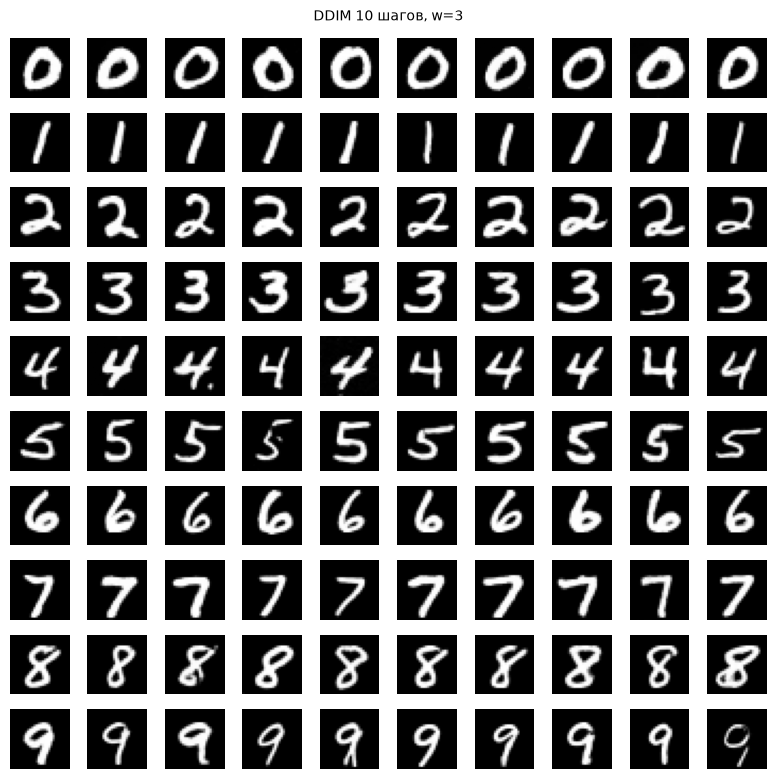

   2: [999, 0]
   5: [999, 749, 500, 250, 0]
  10: [999, 888, 777, 666, 555, 444, 333, 222, 111, 0]
  20: [999, 946, 894, 841, 789, 736, 684, 631, 578, 526, 473, 421, 368, 315, 263, 210, 158, 105, 53, 0]
  50: [999, 979, 958, 938, 917, 897, 877, 856, 836, 816, 795, 775, 754, 734, 714, 693, 673, 652, 632, 612, 591, 571, 550, 530, 510, 489, 469, 449, 428, 408, 387, 367, 347, 326, 306, 285, 265, 245, 224, 204, 183, 163, 143, 122, 102, 82, 61, 41, 20, 0]
 100: [999, 989, 979, 969, 959, 949, 938, 928, 918, 908, 898, 888, 878, 868, 858, 848, 838, 827, 817, 807, 797, 787, 777, 767, 757, 747, 737, 727, 716, 706, 696, 686, 676, 666, 656, 646, 636, 626, 616, 605, 595, 585, 575, 565, 555, 545, 535, 525, 515, 505, 494, 484, 474, 464, 454, 444, 434, 424, 414, 404, 394, 383, 373, 363, 353, 343, 333, 323, 313, 303, 293, 283, 272, 262, 252, 242, 232, 222, 212, 202, 192, 182, 172, 161, 151, 141, 131, 121, 111, 101, 91, 81, 71, 61, 50, 40, 30, 20, 10, 0]
{'boundary_err': 0.0, 'max_transition_err': 4.291

In [4]:
# Задание 3. Сетка DDIM и граничный переход
def make_timesteps(n_steps, T=None):
    """Строго убывающая сетка из n_steps целых t: равномерно от T−1 до 0 (2 ≤ n_steps ≤ T).
    После последнего элемента sampler делает граничный переход в s = −1."""
    T = T_STEPS if T is None else T
    assert 2 <= n_steps <= T, n_steps
    ts = np.round(np.linspace(T - 1, 0, n_steps)).astype(int).tolist()
    assert all(a > b for a, b in zip(ts, ts[1:])), f'сетка не строго убывает: {ts}'
    assert ts[0] == T - 1 and ts[-1] == 0
    return ts


def abar(t):
    """ᾱ_t с граничным условием ᾱ_{−1} = 1 (чистые данные после последнего шага)."""
    return 1.0 if t < 0 else AB[t].item()


def ddim_step(x, eps, t, s):
    """Детерминированный DDIM-переход t → s (η = 0): x̂0 = (x_t − sqrt(1−ᾱ_t)ε̂)/sqrt(ᾱ_t),
    x_s = sqrt(ᾱ_s)x̂0 + sqrt(1−ᾱ_s)ε̂. При s = −1: ᾱ_s = 1 и x_s = x̂0."""
    ab_t, ab_s = abar(t), abar(s)
    x0 = (x - math.sqrt(1 - ab_t) * eps) / math.sqrt(ab_t)
    return math.sqrt(ab_s) * x0 + math.sqrt(1 - ab_s) * eps, x0


def next_t(timesteps, i):
    return timesteps[i + 1] if i + 1 < len(timesteps) else -1


@torch.no_grad()
def ddim_sample(net, labels, w, x_start, timesteps, counter=None):
    """DDIM по произвольной строго убывающей сетке; тот же denoiser и CFG, что у DDPM."""
    net.eval()
    x = x_start.to(DEVICE).clone()
    y = labels.to(DEVICE)
    for i, t in enumerate(timesteps):
        tt = torch.full((x.shape[0],), t, device=DEVICE, dtype=torch.long)
        x, _ = ddim_step(x, guided_eps(net, x, tt, y, w, counter), t, next_t(timesteps, i))
    return x.clamp(-1, 1).cpu()


@torch.no_grad()
def ddpm_sample(net, labels, w, x_start, generator, counter=None):
    """Ancestral DDPM lab 17 (σ_t² = β̃_t, все T шагов) — стохастический baseline с максимальным NFE."""
    net.eval()
    betas_, alphas_, abar_ = SCHED['betas'].tolist(), SCHED['alphas'].tolist(), AB.tolist()
    var_ = SCHED['posterior_var'].tolist()
    x = x_start.to(DEVICE).clone()
    y = labels.to(DEVICE)
    for i in reversed(range(T_STEPS)):
        t = torch.full((x.shape[0],), i, device=DEVICE, dtype=torch.long)
        eps = guided_eps(net, x, t, y, w, counter)
        x = (x - betas_[i] / math.sqrt(1 - abar_[i]) * eps) / math.sqrt(alphas_[i])
        if i > 0:
            x = x + math.sqrt(var_[i]) * torch.randn(x.shape, device=DEVICE, generator=generator)
    return x.clamp(-1, 1).cpu()


def save_grid(images, nrow, path, title=None):
    n = len(images); ncol = math.ceil(n / nrow)
    fig, axes = plt.subplots(nrow, ncol, figsize=(0.75 * ncol + 0.4, 0.75 * nrow + 0.4), squeeze=False)
    for k, ax in enumerate(axes.flat):
        ax.axis('off')
        if k < n:
            ax.imshow(images[k, 0], cmap='gray', vmin=-1, vmax=1)
    if title:
        fig.suptitle(title, fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=110)
    return fig


# --- Сетки: строго убывают, начинаются в T−1, заканчиваются в 0 ---
grid_report = {}
for n in sorted(set(DDIM_STEPS + DPM_STEPS + [TEACHER_STEPS, STUDENT_STEPS, 2])):
    ts = make_timesteps(n)
    assert len(ts) == n and len(set(ts)) == n
    grid_report[str(n)] = ts
assert make_timesteps(T_STEPS) == list(range(T_STEPS - 1, -1, -1)), 'n = T должна давать полную DDPM-сетку'

# --- Граница ᾱ(−1) = 1: последний переход возвращает ровно x̂0 ---
assert abar(-1) == 1.0
chk_gen = torch.Generator().manual_seed(SEED + 11)
x_chk = torch.randn((8, 1, 28, 28), generator=chk_gen)
e_chk = torch.randn((8, 1, 28, 28), generator=chk_gen)
x_last, x0_last = ddim_step(x_chk, e_chk, 0, -1)
assert torch.equal(x_last, x0_last), 'при s=−1 DDIM обязан вернуть x̂0'
manual_x0 = (x_chk - math.sqrt(1 - abar(0)) * e_chk) / math.sqrt(abar(0))
boundary_err = (x_last - manual_x0).abs().max().item()
assert boundary_err < 1e-6, boundary_err

# --- С истинным ε DDIM-переход точно переводит q(x_t|x0) в q(x_s|x0) (real MNIST test) ---
real_x0 = X_test[:8]
transition_errs = []
for t, s in [(T_STEPS - 1, T_STEPS // 2), (T_STEPS // 2, T_STEPS // 10), (T_STEPS // 10, 0), (0, -1)]:
    xt = math.sqrt(abar(t)) * real_x0 + math.sqrt(1 - abar(t)) * e_chk
    xs_expected = math.sqrt(abar(s)) * real_x0 + math.sqrt(1 - abar(s)) * e_chk
    xs, x0_hat = ddim_step(xt, e_chk, t, s)
    transition_errs.append({'t': t, 's': s, 'x_s_max_abs_err': (xs - xs_expected).abs().max().item(),
                            'x0_max_abs_err': (x0_hat - real_x0).abs().max().item()})
assert max(r['x_s_max_abs_err'] for r in transition_errs) < 1e-3, transition_errs

# --- Пробный DDIM на протокольном шуме ---
ddim_counter = new_counter()
cuda_sync(); t0 = time.time()
x_ddim_probe = ddim_sample(teacher, sample_labels, GUIDANCE, x_T, make_timesteps(STUDENT_STEPS), ddim_counter)
cuda_sync(); ddim_probe_sec = time.time() - t0
probe_nfe = (ddim_counter['cond'] + ddim_counter['uncond']) / N_SAMPLES
assert probe_nfe == 2 * STUDENT_STEPS and ddim_counter['forward_calls'] == STUDENT_STEPS
save_grid(x_ddim_probe, 10, FIG_DIR / f'ddim{STUDENT_STEPS}_probe.png', f'DDIM {STUDENT_STEPS} шагов, w={GUIDANCE:g}')
plt.show()

save_json('ddim_grid.json', {'rule': 'round(linspace(T-1, 0, n)), затем s = -1 с alpha_bar(-1) = 1',
                             'T': T_STEPS, 'grids': grid_report, 'boundary_max_abs_err': boundary_err,
                             'true_eps_transitions': transition_errs,
                             'probe': {'steps': STUDENT_STEPS, 'nfe_per_sample': probe_nfe,
                                       'seconds': ddim_probe_sec}})
for n, ts in grid_report.items():
    print(f'{n:>4}: {ts}')
print({'boundary_err': boundary_err, 'max_transition_err': max(r['x_s_max_abs_err'] for r in transition_errs),
       'probe_nfe': probe_nfe, 'probe_sec': round(ddim_probe_sec, 3)})

#### Пояснение к заданию 3: как DDIM проходит 10 шагов

Сетка: `999 → 888 → 777 → 666 → 555 → 444 → 333 → 222 → 111 → 0 → −1`. На вход первого шага подаётся чистый шум $x_T$, на вход каждого следующего — картинка, собранная предыдущим шагом. На каждом шаге $t \to s$:

1. **Оценка шума.** Сеть смотрит на текущую картинку $x_t$ и заново оценивает шум в ней: $\hat\epsilon = \hat\epsilon_u + w(\hat\epsilon_c - \hat\epsilon_u)$. Это 2 вызова сети, с меткой и без, при $w=3$.
2. **Оценка готовой цифры.** Предсказанный шум вычитается: $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$.
3. **Сборка картинки следующего уровня.** Цифра и тот же шум смешиваются в пропорциях шага $s$: $x_s = \sqrt{\bar\alpha_s}\,\hat x_0 + \sqrt{1-\bar\alpha_s}\,\hat\epsilon$. В отличие от DDPM, свежий случайный шум не добавляется, поэтому результат полностью задаётся $x_T$.

Доли сигнала и шума в картинке на каждом шаге (из расписания teacher):

| шаг | t | доля картинки $\sqrt{\bar\alpha_t}$ | доля шума $\sqrt{1-\bar\alpha_t}$ | что видно в $x_t$ |
|---|---|---|---|---|
| 1 | 999 | 0.006 | 1.000 | чистый шум |
| 2 | 888 | 0.018 | 1.000 | шум |
| 3 | 777 | 0.047 | 0.999 | шум, намечается пятно |
| 4 | 666 | 0.105 | 0.995 | грубый силуэт |
| 5 | 555 | 0.208 | 0.978 | общая форма цифры |
| 6 | 444 | 0.365 | 0.931 | форма различима |
| 7 | 333 | 0.565 | 0.826 | штрихи |
| 8 | 222 | 0.773 | 0.635 | цифра чёткая, шум заметен |
| 9 | 111 | 0.935 | 0.356 | почти чистая |
| 10 | 0 | 1.000 | 0.010 | шум почти исчез |
| — | −1 | 1 | 0 | ответ: $x = \hat x_0$ |

От шага к шагу доля картинки растёт от 0.006 до 1, а доля шума падает от 1 до 0. Поэтому влияние шума на итог уменьшается. На ранних шагах сеть решает, какой будет цифра в целом: класс, наклон, толщина. На поздних шагах шума мало, и она только дорисовывает детали. На последнем переходе $\bar\alpha_{-1}=1$, поэтому шум не подмешивается вовсе и на выходе остаётся оценка $\hat x_0$.

Итого 10 шагов × 2 вызова = **20 NFE** на картинку вместо 2000 у DDPM. Чем меньше шагов, тем длиннее каждый прыжок, тем сильнее «устаревает» оценка $\hat\epsilon$ на отрезке и тем больше ошибка. Это измеряется в заданиях 6–7.


### Задание 4. DPM-Solver++ на той же модели

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Добавьте solver с тем же epsilon-predictor и beta schedule.

**Результат.** Проверяемое состояние «DPM-Solver++ на той же модели» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Добавьте solver с тем же epsilon-predictor и beta schedule» и его результат доступен следующему этапу.

**DPM-Solver++(2M) на той же модели**

- **Что делали**: добавили второй быстрый sampler — DPM-Solver++ второго порядка. Модель, расписание и guidance те же, но шаг учитывает ещё и оценку цифры с прошлого шага (экстраполяция). Проверили, что без поправки второго порядка он совпадает с DDIM, и сравнили оба с эталоном DDIM 100 на 10 шагах.
- **Зачем**: проверить, можно ли при том же числе вызовов сети точнее пройти путь от шума к картинке, не обучая ничего заново.
- **Результат**: dpm_solver_check.json и dpm_solver_vs_ddim.png. Число вызовов то же — 20 на картинку (10 с меткой + 10 без). Первый порядок совпадает с DDIM: на каждом шаге в float64 с ошибкой 2.7e-16, на всём прогоне RMSE 0.0004. Второй порядок меняет траекторию (RMSE 0.144 от DDIM). Отклонение от эталона DDIM 100: DDIM 10 — 0.118, DPM-Solver++ 10 — 0.081, примерно на 30% точнее.

DPM-Solver++ устроен как DDIM, но на каждом шаге использует ещё и прошлую оценку цифры.

**Напоминание: шаг DDIM.**

1. Сеть оценивает шум $\hat\epsilon$ → получаем оценку цифры $\hat x_0$.
2. Собираем картинку следующего уровня из $\hat x_0$ и шума.

Неявное допущение: пока прыгаем с 999 на 888, оценка цифры $\hat x_0$ не меняется. На коротком прыжке это почти правда, на длинном — нет.

**Что добавляет DPM-Solver++.** Он запоминает $\hat x_0$ с прошлого шага и сравнивает с текущей:

- прошлый шаг: цифра виделась как $\hat x_0^{\text{прошлый}}$;
- текущий шаг: цифра видится как $\hat x_0^{\text{сейчас}}$;
- разница между ними — направление, в котором оценка цифры меняется.

Вместо $\hat x_0^{\text{сейчас}}$ он подставляет в формулу шага экстраполированную оценку $D$ — с поправкой на то, куда цифра движется:

$$D = \Big(1 + \tfrac{1}{2r}\Big)\,\hat x_0^{\text{сейчас}} - \tfrac{1}{2r}\,\hat x_0^{\text{прошлый}}$$

Здесь $r$ — отношение длины прошлого прыжка к текущему (длины меряются в логарифме отношения сигнал/шум). Если оценка цифры за прошлый шаг сдвинулась «вправо», $D$ берётся ещё немного правее.

Дальше картинка следующего уровня собирается по той же схеме, что в DDIM, только с $D$ вместо $\hat x_0$.


DDIM 100 является эталоном. Значения пикселей сравнивается в DDIM10 и DPM++ 10. Второй на 31% ближе к эталону

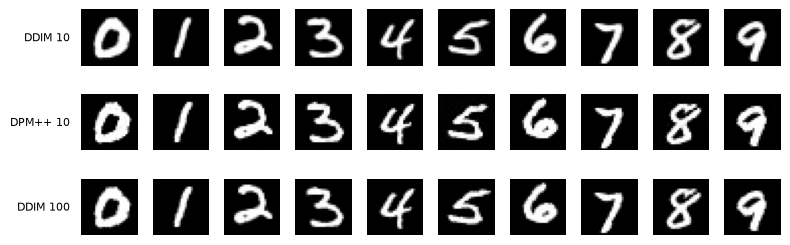

Сетка 10 шагов: [999, 888, 777, 666, 555, 444, 333, 222, 111, 0] → −1
NFE на картинку: 20 (cond 10 + uncond 10) — одинаково у DDIM и DPM-Solver++

Проверки реализации:
  1-й порядок vs DDIM, один переход (float64), отн. ошибка: 2.7e-16  → формулы совпадают
  1-й порядок vs DDIM, весь прогон (float32), RMSE:        0.0004   → только округление
  2-й порядок vs DDIM, весь прогон, RMSE:                  0.1442   → поправка меняет траекторию

Близость к эталону DDIM 100 steps при общем x_T (RMSE пикселей в [-1, 1], меньше — точнее):
  DDIM 10                0.1181  ████████████████████████
  DPM-Solver++(2M) 10    0.0815  ████████████████
  → DPM-Solver++ ближе к эталону на 31% при том же NFE
Время DPM-Solver++ 10 шагов на 100 картинок: 0.37 с


In [5]:
# Задание 4. DPM-Solver++ на той же модели
def alpha_sigma_lambda(t):
    """α_t = sqrt(ᾱ_t), σ_t = sqrt(1−ᾱ_t), λ_t = log(α_t/σ_t) из того же beta-schedule; при t = −1: σ = 0, λ = +∞."""
    if t < 0:
        return 1.0, 0.0, math.inf
    ab = abar(t)
    return math.sqrt(ab), math.sqrt(1 - ab), 0.5 * (math.log(ab) - math.log1p(-ab))


@torch.no_grad()
def dpm_solver_pp_sample(net, labels, w, x_start, timesteps, order=2, counter=None):
    """DPM-Solver++(2M) (Lu et al., 2022) в data-prediction форме с тем же ε-предсказателем и CFG:
    x̂0 = (x_t − σ_t ε̂)/α_t,  x_s = (σ_s/σ_t) x_t + α_s (1 − e^{−h}) D,  h = λ_s − λ_t,
    D = (1 + 1/2r) x̂0_t − (1/2r) x̂0_prev,  r = h_prev / h. Первый шаг — 1-го порядка (нет истории),
    последний переход в s = −1 (σ_s = 0, h = ∞) — тоже 1-го порядка: x = x̂0. order=1 совпадает с DDIM."""
    net.eval()
    x = x_start.to(DEVICE).clone()
    y = labels.to(DEVICE)
    x0_prev, h_prev = None, None
    for i, t in enumerate(timesteps):
        s = next_t(timesteps, i)
        tt = torch.full((x.shape[0],), t, device=DEVICE, dtype=torch.long)
        eps = guided_eps(net, x, tt, y, w, counter)
        a_t, sig_t, lam_t = alpha_sigma_lambda(t)
        a_s, sig_s, lam_s = alpha_sigma_lambda(s)
        x0 = (x - sig_t * eps) / a_t
        if s < 0:
            x = x0
            break
        h = lam_s - lam_t
        if order == 1 or x0_prev is None:
            D = x0
        else:
            r = h_prev / h
            D = (1 + 1 / (2 * r)) * x0 - (1 / (2 * r)) * x0_prev
        x = (sig_s / sig_t) * x + a_s * (-math.expm1(-h)) * D
        x0_prev, h_prev = x0, h
    return x.clamp(-1, 1).cpu()


# --- λ_t строго растёт при движении к данным, h > 0 на каждом шаге сетки ---
lams = [alpha_sigma_lambda(t)[2] for t in range(T_STEPS)]
assert all(a > b for a, b in zip(lams, lams[1:])), 'λ_t должна убывать по t'

dpm_ts = make_timesteps(STUDENT_STEPS)
c_ddim, c_dpm1, c_dpm2 = new_counter(), new_counter(), new_counter()
x_ddim = ddim_sample(teacher, sample_labels, GUIDANCE, x_T, dpm_ts, c_ddim)
x_dpm1 = dpm_solver_pp_sample(teacher, sample_labels, GUIDANCE, x_T, dpm_ts, order=1, counter=c_dpm1)
cuda_sync(); t0 = time.time()
x_dpm2 = dpm_solver_pp_sample(teacher, sample_labels, GUIDANCE, x_T, dpm_ts, order=2, counter=c_dpm2)
cuda_sync(); dpm_sec = time.time() - t0

# Тот же ε-предсказатель и CFG: одинаковое число обращений
assert c_ddim == c_dpm1 == c_dpm2, (c_ddim, c_dpm1, c_dpm2)

# 1-й порядок аналитически равен DDIM: каждый переход сетки в float64 при одних x_t и ε̂
eq_gen = torch.Generator().manual_seed(SEED + 12)
x64 = torch.randn((4, 1, 28, 28), generator=eq_gen, dtype=torch.float64)
e64 = torch.randn((4, 1, 28, 28), generator=eq_gen, dtype=torch.float64)
step_equiv_err = 0.0
for i, t in enumerate(dpm_ts):
    s = next_t(dpm_ts, i)
    (a_t, sig_t, lam_t), (a_s, sig_s, lam_s) = alpha_sigma_lambda(t), alpha_sigma_lambda(s)
    x0 = (x64 - sig_t * e64) / a_t
    x_dpm_step = x0 if s < 0 else (sig_s / sig_t) * x64 + a_s * (-math.expm1(-(lam_s - lam_t))) * x0
    x_ddim_step, _ = ddim_step(x64, e64, t, s)
    step_equiv_err = max(step_equiv_err, ((x_dpm_step - x_ddim_step).abs().max() / (x_ddim_step.abs().max() + 1)).item())
assert step_equiv_err < 1e-9, step_equiv_err

# Полный прогон во float32: остаётся только округление (при t≈T−1 деление на α_t≈0.006), усиленное сетью
rmse = lambda a, b: (a - b).pow(2).mean().sqrt().item()
order1_vs_ddim = rmse(x_dpm1, x_ddim)
order2_vs_ddim = rmse(x_dpm2, x_ddim)
assert order1_vs_ddim < 5e-3, f'DPM-Solver++ 1-го порядка должен совпадать с DDIM, rmse={order1_vs_ddim}'
assert order2_vs_ddim > 5 * max(order1_vs_ddim, 1e-6), '2-й порядок не изменил траекторию — поправка не работает'

# Эталон: DDIM с максимальным числом шагов (100) из того же x_T. Мелкие шаги почти не ошибаются, поэтому это
# приближённо «точная» траектория; RMSE до неё показывает ошибку, внесённую крупными прыжками 10-шагового sampler
ref_steps = max(DDIM_STEPS)
x_ref = ddim_sample(teacher, sample_labels, GUIDANCE, x_T, make_timesteps(ref_steps))
dpm_check = {'steps': STUDENT_STEPS, 'grid': dpm_ts, 'guidance': GUIDANCE,
             'nfe_per_sample': (c_dpm2['cond'] + c_dpm2['uncond']) / N_SAMPLES,
             'nfe_cond_per_sample': c_dpm2['cond'] / N_SAMPLES, 'nfe_uncond_per_sample': c_dpm2['uncond'] / N_SAMPLES,
             'step_equivalence_rel_err_float64': step_equiv_err,
             'order1_vs_ddim_rmse': order1_vs_ddim, 'order2_vs_ddim_rmse': order2_vs_ddim,
             'reference': f'DDIM {ref_steps} steps',
             'rmse_to_reference': {'DDIM': rmse(x_ddim, x_ref), 'DPM-Solver++(2M)': rmse(x_dpm2, x_ref)},
             'seconds_dpm2': dpm_sec}
save_json('dpm_solver_check.json', dpm_check)

fig, axes = plt.subplots(3, 10, figsize=(8, 2.8))
first_idx = torch.arange(10) * SAMPLES_PER_CLASS
for r, (x, name) in enumerate([(x_ddim, f'DDIM {STUDENT_STEPS}'), (x_dpm2, f'DPM++ {STUDENT_STEPS}'),
                               (x_ref, f'DDIM {ref_steps}')]):
    for c in range(10):
        axes[r, c].imshow(x[first_idx[c], 0], cmap='gray', vmin=-1, vmax=1); axes[r, c].axis('off')
    axes[r, 0].text(-6, 14, name, ha='right', va='center', fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'dpm_solver_vs_ddim.png', dpi=120); plt.show()
ref_rmse = dpm_check['rmse_to_reference']
print(f"Сетка {STUDENT_STEPS} шагов: {dpm_ts} → −1")
print(f"NFE на картинку: {dpm_check['nfe_per_sample']:.0f} (cond {dpm_check['nfe_cond_per_sample']:.0f} + "
      f"uncond {dpm_check['nfe_uncond_per_sample']:.0f}) — одинаково у DDIM и DPM-Solver++")
print()
print('Проверки реализации:')
print(f"  1-й порядок vs DDIM, один переход (float64), отн. ошибка: {step_equiv_err:.1e}  → формулы совпадают")
print(f"  1-й порядок vs DDIM, весь прогон (float32), RMSE:        {order1_vs_ddim:.4f}   → только округление")
print(f"  2-й порядок vs DDIM, весь прогон, RMSE:                  {order2_vs_ddim:.4f}   → поправка меняет траекторию")
print()
print(f"Близость к эталону {dpm_check['reference']} при общем x_T (RMSE пикселей в [-1, 1], меньше — точнее):")
for name, v in ref_rmse.items():
    print(f"  {name + ' ' + str(STUDENT_STEPS):22s} {v:.4f}  {'█' * round(v * 200)}")
gain = 1 - ref_rmse['DPM-Solver++(2M)'] / ref_rmse['DDIM']
print(f"  → DPM-Solver++ {'ближе' if gain > 0 else 'дальше'} к эталону на {abs(gain):.0%} при том же NFE")
print(f"Время DPM-Solver++ {STUDENT_STEPS} шагов на {N_SAMPLES} картинок: {dpm_sec:.2f} с")

DPM-Solver++ применяет изменения к изображения с учетом изменеий с предыдущего шага

### Задание 5. Инварианты детерминизма sampler

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Проверьте конец сетки и совпадение двух запусков DDIM при одинаковом шуме.

**Результат.** Проверяемое состояние «Инварианты детерминизма sampler» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Проверьте конец сетки и совпадение двух запусков DDIM при одинаковом шуме» и его результат доступен следующему этапу.

**Детерминизм sampler**

- **Что делали**: проверили, что каждая сетка начинается с 999, заканчивается на 0 и затем переходит в −1. Запустили DDIM дважды на одном шуме, нарочно сбив генератор случайных чисел между запусками. Повторили для DPM-Solver++, сравнили с другим шумом, с половиной батча и со случайными шагами DDPM при одном и разных seed.
- **Зачем**: в заданиях 6–10 sampler сравниваются на одном шуме; это корректно, только если результат полностью определяется шумом и не зависит от скрытой случайности и состава батча.
- **Результат**: determinism.json. Два запуска DDIM совпали бит в бит (разница 0.0), DPM-Solver++ — тоже 0.0. Другой шум даёт другую картинку (RMSE 0.54). Половина батча отличается лишь округлением GPU (RMSE 0.0003, в 1500 раз меньше). DDPM с тем же seed совпадает (0.0), с другим — нет (0.053). Сетка student заканчивается на 53 → −1: это ожидаемо, каждый его шаг заменяет два шага teacher.

In [6]:
# Задание 5. Инварианты детерминизма sampler
det = {}

# --- 1. Конец сетки: каждая используемая сетка заканчивается в t=0, затем граничный переход в s=−1 ---
used_grids = {f'DDIM/DPM {n}': make_timesteps(n) for n in sorted(set(DDIM_STEPS + DPM_STEPS + [TEACHER_STEPS]))}
used_grids[f'student {STUDENT_STEPS} (teacher {TEACHER_STEPS}[::2])'] = make_timesteps(TEACHER_STEPS)[::2]
det['grids'] = {}
for name, ts in used_grids.items():
    transitions = [(t, next_t(ts, i)) for i, t in enumerate(ts)]
    assert transitions[-1][1] == -1 and all(s < t for t, s in transitions)
    det['grids'][name] = {'first': ts[0], 'last': ts[-1], 'final_transition': transitions[-1], 'n': len(ts)}
assert all(g['first'] == T_STEPS - 1 for g in det['grids'].values())
assert all(g['last'] == 0 for n, g in det['grids'].items() if not n.startswith('student'))

# --- 2. Два запуска DDIM на одном x_T совпадают; глобальный RNG между ними сдвинут намеренно ---
det_ts = make_timesteps(STUDENT_STEPS)
run_a = ddim_sample(teacher, sample_labels, GUIDANCE, x_T, det_ts)
torch.randn(1000); torch.manual_seed(SEED + 999)        # скрытая случайность в DDIM проявилась бы здесь
run_b = ddim_sample(teacher, sample_labels, GUIDANCE, make_x_T(), det_ts)
det['ddim_repeat_max_abs'] = (run_a - run_b).abs().max().item()
det['ddim_repeat_bitwise_equal'] = bool(torch.equal(run_a, run_b))
assert det['ddim_repeat_max_abs'] < 1e-5, det['ddim_repeat_max_abs']

# --- 3. DPM-Solver++ тоже детерминирован ---
dpm_a = dpm_solver_pp_sample(teacher, sample_labels, GUIDANCE, x_T, det_ts)
dpm_b = dpm_solver_pp_sample(teacher, sample_labels, GUIDANCE, x_T, det_ts)
det['dpm_repeat_max_abs'] = (dpm_a - dpm_b).abs().max().item()
assert det['dpm_repeat_max_abs'] < 1e-5

# --- 4. Другой шум → другой результат (sampler не игнорирует x_T) ---
other_T = torch.randn(x_T.shape, generator=torch.Generator().manual_seed(SAMPLE_SEED + 100))
run_other = ddim_sample(teacher, sample_labels, GUIDANCE, other_T, det_ts)
det['ddim_other_noise_rms'] = (run_a - run_other).pow(2).mean().sqrt().item()
assert det['ddim_other_noise_rms'] > 0.05

# --- 5. Результат сэмпла не зависит от состава батча (GroupNorm/attention — по сэмплу) с точностью до округления ---
half = N_SAMPLES // 2
run_half = ddim_sample(teacher, sample_labels[:half], GUIDANCE, x_T[:half], det_ts)
det['batch_invariance_max_abs'] = (run_half - run_a[:half]).abs().max().item()
det['batch_invariance_rmse'] = (run_half - run_a[:half]).pow(2).mean().sqrt().item()
# Ядра для другого размера батча округляют иначе: допускаем численный, но не содержательный сдвиг
assert det['batch_invariance_rmse'] < 0.1 * det['ddim_other_noise_rms'], det['batch_invariance_rmse']

# --- 6. Контраст: короткий стохастический DDPM-путь зависит от генератора z_t, DDIM — нет ---
DDPM_TAIL_STEPS = 3
def ddpm_tail(gen):   # последние шаги ancestral sampler на одном x_t — дешёвая проверка стохастичности
    x = run_a[:4].to(DEVICE).clone(); y = sample_labels[:4].to(DEVICE)
    with torch.no_grad():
        for i in reversed(range(DDPM_TAIL_STEPS)):
            t = torch.full((4,), i, device=DEVICE, dtype=torch.long)
            eps = guided_eps(teacher, x, t, y, GUIDANCE)
            x = (x - SCHED['betas'][i].item() / math.sqrt(1 - abar(i)) * eps) / math.sqrt(SCHED['alphas'][i].item())
            if i > 0:
                x = x + math.sqrt(SCHED['posterior_var'][i].item()) * torch.randn(x.shape, device=DEVICE, generator=gen)
    return x.cpu()
same_a, same_b = ddpm_tail(make_ddpm_generator()), ddpm_tail(make_ddpm_generator())
diff_seed = ddpm_tail(torch.Generator(device=DEVICE).manual_seed(DDPM_NOISE_SEED + 1))
det['ddpm_same_seed_max_abs'] = (same_a - same_b).abs().max().item()
det['ddpm_other_seed_max_abs'] = (same_a - diff_seed).abs().max().item()
assert det['ddpm_same_seed_max_abs'] < 1e-5 and det['ddpm_other_seed_max_abs'] > 1e-4

save_json('determinism.json', det)
for k, v in det.items():
    if k != 'grids':
        print(f'{k:28s} {v}')
for name, g in det['grids'].items():
    print(f'{name:40s} {g}')

ddim_repeat_max_abs          0.0
ddim_repeat_bitwise_equal    True
dpm_repeat_max_abs           0.0
ddim_other_noise_rms         0.538827657699585
batch_invariance_max_abs     0.014926761388778687
batch_invariance_rmse        0.00034117340692318976
ddpm_same_seed_max_abs       0.0
ddpm_other_seed_max_abs      0.05315972864627838
DDIM/DPM 5                               {'first': 999, 'last': 0, 'final_transition': (0, -1), 'n': 5}
DDIM/DPM 10                              {'first': 999, 'last': 0, 'final_transition': (0, -1), 'n': 10}
DDIM/DPM 20                              {'first': 999, 'last': 0, 'final_transition': (0, -1), 'n': 20}
DDIM/DPM 50                              {'first': 999, 'last': 0, 'final_transition': (0, -1), 'n': 50}
DDIM/DPM 100                             {'first': 999, 'last': 0, 'final_transition': (0, -1), 'n': 100}
student 10 (teacher 20[::2])             {'first': 999, 'last': 53, 'final_transition': (53, -1), 'n': 10}


### Задание 6. Измеримые бюджеты sampling

*Вес: 1 балл.*

**Постановка.** Время и качество измеряются на одном batch; количество NFE учитывает conditional и unconditional обращения отдельно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте class agreement и внутриклассовое разнообразие PNG при равном начальном шуме, учитывайте NFE.

**Результат.** Проверяемое состояние «Измеримые бюджеты sampling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте class agreement и внутриклассовое разнообразие PNG при равном начальном шуме, учитывайте NFE» и его результат доступен следующему этапу.

**Бюджеты sampling: время, NFE, качество**

- **Что делали**: на одном батче из 100 картинок, с общим шумом, метками и w = 3, запустили DDPM 1000, DDIM 100/50/20/10/5 и DPM-Solver++ 20/10/5. Для каждого измерили время, число вызовов сети (с меткой и без отдельно), узнаваемость цифр судьёй, его уверенность, разнообразие внутри класса и отклонение от эталона DDIM 100. Метрики считали по сохранённым PNG.
- **Зачем**: понять, сколько качества теряется при сокращении числа шагов и какой sampler выгоднее при одинаковом бюджете.
- **Результат**: budgets.csv, budgets.json, PNG каждой конфигурации, samplers_same_noise.png. Время пропорционально числу вызовов: DDPM 1000 — 37.3 с, DDIM 10 — 0.37 с (в 100 раз быстрее). Узнаваемость почти не страдает: DDIM 5 — 1.00, хуже всех DPM-Solver++ 5 — 0.96. Разнообразие DDIM падает с 0.284 (100 шагов) до 0.210 (5 шагов), у DPM-Solver++ держится на 0.29–0.30 (у реальных цифр 0.312). Отклонение от эталона при 10 шагах: DDIM 0.118, DPM-Solver++ 0.082.

DDPM 1000  NFE=  2000 sec=  37.30 acc=1.000 p(y|x)=1.000 div=0.289
DDIM 100   NFE=   200 sec=   3.66 acc=0.990 p(y|x)=0.993 div=0.284
DDIM 50    NFE=   100 sec=   1.83 acc=1.000 p(y|x)=0.995 div=0.282
DDIM 20    NFE=    40 sec=   0.73 acc=1.000 p(y|x)=1.000 div=0.272
DDIM 10    NFE=    20 sec=   0.37 acc=1.000 p(y|x)=1.000 div=0.255
DDIM 5     NFE=    10 sec=   0.18 acc=1.000 p(y|x)=1.000 div=0.210
DPM++ 20   NFE=    40 sec=   0.73 acc=0.990 p(y|x)=0.991 div=0.293
DPM++ 10   NFE=    20 sec=   0.37 acc=0.990 p(y|x)=0.990 div=0.299
DPM++ 5    NFE=    10 sec=   0.18 acc=0.960 p(y|x)=0.950 div=0.293


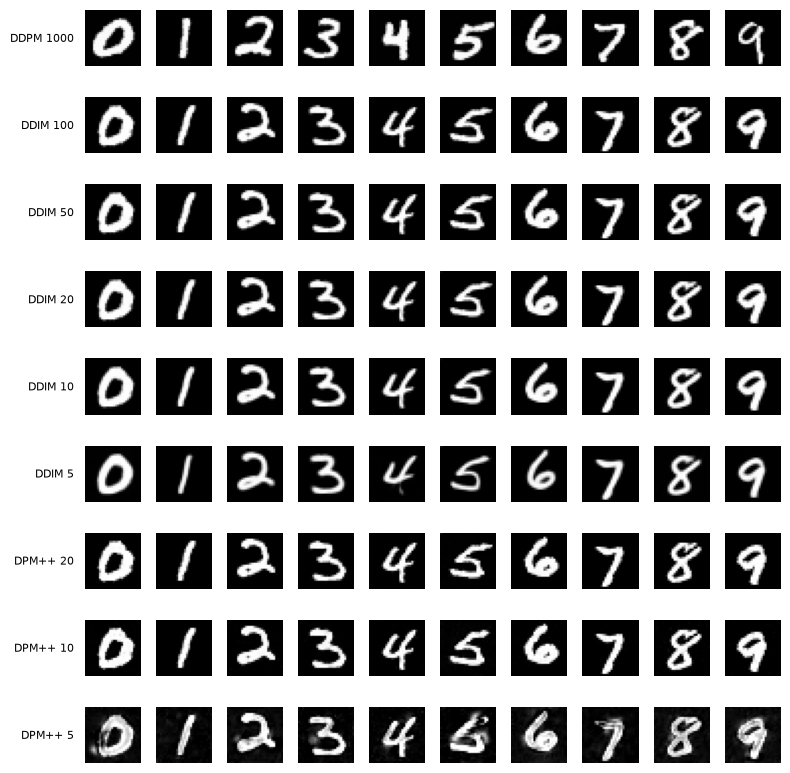

real test diversity = 0.312; classifier test acc = 0.9870
config       NFE  cond   unc     sec    acc  p(y|x)    div rmse_ref
DDPM 1000   2000  1000  1000   37.30  1.000   1.000  0.289      nan
DDIM 100     200   100   100    3.66  0.990   0.993  0.284   0.0000
DDIM 50      100    50    50    1.83  1.000   0.995  0.282   0.0341
DDIM 20       40    20    20    0.73  1.000   1.000  0.272   0.0785
DDIM 10       20    10    10    0.37  1.000   1.000  0.255   0.1182
DDIM 5        10     5     5    0.18  1.000   1.000  0.210   0.2521
DPM++ 20      40    20    20    0.73  0.990   0.991  0.293   0.0425
DPM++ 10      20    10    10    0.37  0.990   0.990  0.299   0.0815
DPM++ 5       10     5     5    0.18  0.960   0.950  0.293   0.2561


In [7]:
# Задание 6. Измеримые бюджеты sampling
from PIL import Image


def to_uint8(x):
    return ((x.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)


def save_png_sheet(u8, path):
    """Без потерь: строка — класс, столбец — номер сэмпла внутри класса, клетка 28×28 без отступов."""
    sheet = u8[:, 0].reshape(10, SAMPLES_PER_CLASS, 28, 28).permute(0, 2, 1, 3).reshape(10 * 28, SAMPLES_PER_CLASS * 28)
    Image.fromarray(sheet.numpy()).save(path)


def load_png_sheet(path):
    sheet = torch.from_numpy(np.array(Image.open(path)))
    return sheet.reshape(10, 28, SAMPLES_PER_CLASS, 28).permute(0, 2, 1, 3).reshape(N_SAMPLES, 1, 28, 28)


def pairwise_rms(x):
    """Средняя попарная RMS-дистанция в пикселях [0, 1] (как в lab 17)."""
    flat = ((x + 1) / 2).flatten(1)
    n = len(flat)
    if n < 2:
        return float('nan')
    return (torch.cdist(flat, flat).sum() / (n * (n - 1)) / math.sqrt(flat.shape[1])).item()


def within_class_diversity(x, labels):
    return float(np.mean([pairwise_rms(x[labels == c]) for c in range(10)]))


def evaluate_png(path):
    """Метрики считаются по сохранённому PNG — ровно по тем картинкам, что попадут в отчёт."""
    x = to_model_range(load_png_sheet(path)[:, 0])
    probs = predict_probs(x)
    pred = probs.argmax(1)
    u = (x + 1) / 2
    return x, probs, {'class_agreement': (pred == sample_labels).float().mean().item(),
                      'mean_target_prob': probs[torch.arange(N_SAMPLES), sample_labels].mean().item(),
                      'within_class_diversity': within_class_diversity(x, sample_labels),
                      'gray_pixel_fraction': ((u > 0.1) & (u < 0.9)).float().mean().item(),
                      'per_class_agreement': [(pred[sample_labels == c] == c).float().mean().item() for c in range(10)]}


def run_sampler(kind, n_steps, net=None, timesteps=None):
    net = teacher if net is None else net
    counter = new_counter()
    cuda_sync(); t0 = time.time()
    if kind == 'DDPM':
        x = ddpm_sample(net, sample_labels, GUIDANCE, x_T, make_ddpm_generator(), counter)
    elif kind == 'DDIM':
        x = ddim_sample(net, sample_labels, GUIDANCE, x_T, timesteps or make_timesteps(n_steps), counter)
    elif kind == 'DPM-Solver++(2M)':
        x = dpm_solver_pp_sample(net, sample_labels, GUIDANCE, x_T, timesteps or make_timesteps(n_steps), counter=counter)
    else:
        raise ValueError(kind)
    cuda_sync()
    return x, counter, time.time() - t0


def measure(name, kind, n_steps, net=None, timesteps=None):
    """Один batch из N_SAMPLES на общих x_T/метках/w: время, NFE (cond и uncond отдельно), PNG и метрики по PNG."""
    x, counter, seconds = run_sampler(kind, n_steps, net, timesteps)
    nfe = (counter['cond'] + counter['uncond']) / N_SAMPLES
    expected = 2 * n_steps  # w=3: обе ветви CFG на каждом шаге
    assert nfe == expected and counter['cond'] == counter['uncond'], (name, counter, expected)
    png_path = PNG_DIR / f"{name.replace(' ', '_').replace('(', '').replace(')', '').replace('+', 'p')}.png"
    save_png_sheet(to_uint8(x), png_path)
    x_png, probs, metrics = evaluate_png(png_path)
    assert (x_png - x).abs().max().item() <= 1 / 127.5 + 1e-6, 'PNG должен совпадать с выходом до квантования'
    row = {'name': name, 'sampler': kind, 'steps': n_steps, 'nfe_per_sample': nfe,
           'nfe_cond_per_sample': counter['cond'] / N_SAMPLES, 'nfe_uncond_per_sample': counter['uncond'] / N_SAMPLES,
           'batched_forward_calls': counter['forward_calls'], 'seconds': seconds,
           'ms_per_sample': 1000 * seconds / N_SAMPLES, 'png': str(png_path), **metrics}
    return row, x_png, probs


# Прогрев: первые вызовы CUDA/cuDNN не должны попасть в замер времени первого sampler
with torch.no_grad():
    for _ in range(3):
        guided_eps(teacher, x_T.to(DEVICE), torch.full((N_SAMPLES,), T_STEPS - 1, device=DEVICE),
                   sample_labels.to(DEVICE), GUIDANCE)
cuda_sync()

CONFIGS = ([('DDPM 1000' if T_STEPS == 1000 else f'DDPM {T_STEPS}', 'DDPM', T_STEPS)]
           + [(f'DDIM {n}', 'DDIM', n) for n in sorted(DDIM_STEPS, reverse=True)]
           + [(f'DPM++ {n}', 'DPM-Solver++(2M)', n) for n in sorted(DPM_STEPS, reverse=True)])
budget_rows, RESULTS = [], {}
for name, kind, n in CONFIGS:
    row, x_png, probs = measure(name, kind, n)
    budget_rows.append(row); RESULTS[name] = {'x': x_png, 'probs': probs}
    print(f"{name:10s} NFE={row['nfe_per_sample']:>6.0f} sec={row['seconds']:>7.2f} "
          f"acc={row['class_agreement']:.3f} p(y|x)={row['mean_target_prob']:.3f} div={row['within_class_diversity']:.3f}")

# Близость к почти точному решению ODE (DDIM с максимальным числом шагов) — для детерминированных sampler
REF_NAME = f'DDIM {max(DDIM_STEPS)}'
for row in budget_rows:
    row['rmse_to_ddim_ref'] = (float('nan') if row['sampler'] == 'DDPM'
                               else (RESULTS[row['name']]['x'] - RESULTS[REF_NAME]['x']).pow(2).mean().sqrt().item())

# Реальные test-картинки — ориентир разнообразия (только сравнение, не выбор настроек)
real_ref_idx = torch.cat([(y_test == c).nonzero().flatten()[:SAMPLES_PER_CLASS] for c in range(10)])
real_diversity = within_class_diversity(X_test[real_ref_idx], y_test[real_ref_idx])

save_json('budgets.json', {'guidance': GUIDANCE, 'n_samples': N_SAMPLES, 'device': DEVICE,
                           'reference_for_rmse': REF_NAME, 'real_test_diversity': real_diversity,
                           'classifier_test_accuracy': cls_json['test_accuracy'], 'rows': budget_rows})
flat_keys = [k for k in budget_rows[0] if k != 'per_class_agreement']
with open(ARTIFACTS / 'budgets.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=flat_keys)
    writer.writeheader(); writer.writerows([{k: r[k] for k in flat_keys} for r in budget_rows])

fig, axes = plt.subplots(len(CONFIGS), 10, figsize=(8, 0.85 * len(CONFIGS) + 0.4))
for r, (name, _, _) in enumerate(CONFIGS):
    for c in range(10):
        axes[r, c].imshow(RESULTS[name]['x'][first_idx[c], 0], cmap='gray', vmin=-1, vmax=1); axes[r, c].axis('off')
    axes[r, 0].text(-6, 14, name, ha='right', va='center', fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'samplers_same_noise.png', dpi=120); plt.show()

print(f'real test diversity = {real_diversity:.3f}; classifier test acc = {cls_json["test_accuracy"]:.4f}')
print(f"{'config':10s} {'NFE':>5} {'cond':>5} {'unc':>5} {'sec':>7} {'acc':>6} {'p(y|x)':>7} {'div':>6} {'rmse_ref':>8}")
for r in budget_rows:
    print(f"{r['name']:10s} {r['nfe_per_sample']:>5.0f} {r['nfe_cond_per_sample']:>5.0f} {r['nfe_uncond_per_sample']:>5.0f} "
          f"{r['seconds']:>7.2f} {r['class_agreement']:>6.3f} {r['mean_target_prob']:>7.3f} "
          f"{r['within_class_diversity']:>6.3f} {r['rmse_to_ddim_ref']:>8.4f}")

### Задание 7. Pareto скорости и качества

*Вес: 1 балл.*

**Постановка.** Время и качество измеряются на одном batch; количество NFE учитывает conditional и unconditional обращения отдельно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите недоминируемые точки только из измеренных времени и точности.

**Результат.** Проверяемое состояние «Pareto скорости и качества» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите недоминируемые точки только из измеренных времени и точности» и его результат доступен следующему этапу.

**Pareto-фронт скорости и качества**

- **Что делали**: по измеренным в задании 6 точкам «время ↔ узнаваемость» нашли недоминируемые: те, для которых нет варианта одновременно не медленнее и не хуже. Отдельно построили фронт по числу вызовов сети и справочно — по уверенности судьи.
- **Зачем**: отсеять заведомо невыгодные варианты и оставить только разумный выбор между скоростью и качеством.
- **Результат**: pareto.json и pareto_teacher.png. Во фронте одна точка — DDIM 5 (0.18 с, узнаваемость 1.00): узнаваемость упирается в потолок 1.0 и не различает sampler. По уверенности судьи во фронт попадают DDPM 1000 и DDIM 5. Из задания 6 видно, что у DDIM 5 самое низкое разнообразие (0.210), поэтому вывод «DDIM 5 лучше всех» верен только по критерию задания.

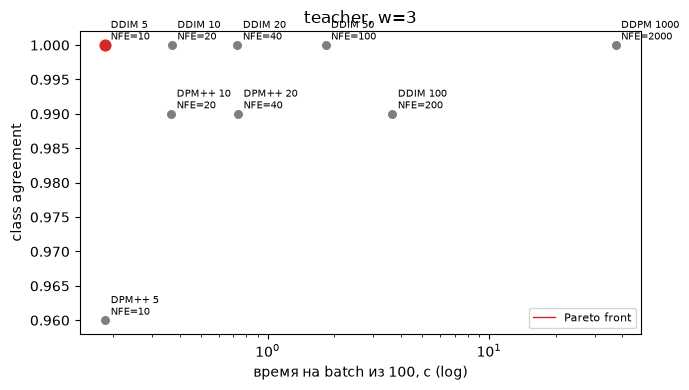

Pareto (время, acc): ['DDIM 5']
Pareto (NFE, acc):   ['DDIM 5']
Pareto (время, p(y|x)), справочно: ['DDPM 1000', 'DDIM 5']
* DDIM 5     sec=   0.18 acc=1.000 p(y|x)=1.000
  DPM++ 5    sec=   0.18 acc=0.960 p(y|x)=0.950
  DPM++ 10   sec=   0.37 acc=0.990 p(y|x)=0.990
  DDIM 10    sec=   0.37 acc=1.000 p(y|x)=1.000
  DDIM 20    sec=   0.73 acc=1.000 p(y|x)=1.000
  DPM++ 20   sec=   0.73 acc=0.990 p(y|x)=0.991
  DDIM 50    sec=   1.83 acc=1.000 p(y|x)=0.995
  DDIM 100   sec=   3.66 acc=0.990 p(y|x)=0.993
  DDPM 1000  sec=  37.30 acc=1.000 p(y|x)=1.000


In [8]:
# Задание 7. Pareto скорости и качества
def pareto_front(rows, cost_key='seconds', quality_key='class_agreement'):
    """Недоминируемые точки: нет другой, у которой cost ≤ и quality ≥, причём хотя бы одно строго.
    Используются только измеренные значения из строк."""
    front = []
    for a in rows:
        dominated = any(b is not a and b[cost_key] <= a[cost_key] and b[quality_key] >= a[quality_key]
                        and (b[cost_key] < a[cost_key] or b[quality_key] > a[quality_key]) for b in rows)
        if not dominated:
            front.append(a['name'])
    return front


def plot_pareto(rows, front, path, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    for r in rows:
        on = r['name'] in front
        ax.scatter(r['seconds'], r['class_agreement'], s=60 if on else 30, c='tab:red' if on else 'tab:gray', zorder=3)
        ax.annotate(f"{r['name']}\nNFE={r['nfe_per_sample']:.0f}", (r['seconds'], r['class_agreement']),
                    fontsize=7, xytext=(4, 4), textcoords='offset points')
    pts = sorted((r['seconds'], r['class_agreement']) for r in rows if r['name'] in front)
    ax.step([p[0] for p in pts], [p[1] for p in pts], where='post', c='tab:red', lw=1, label='Pareto front')
    ax.set_xscale('log'); ax.set_xlabel(f'время на batch из {N_SAMPLES}, с (log)'); ax.set_ylabel('class agreement')
    ax.set_title(title); ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(path, dpi=120)
    return fig


front_time = pareto_front(budget_rows, 'seconds', 'class_agreement')
front_nfe = pareto_front(budget_rows, 'nfe_per_sample', 'class_agreement')
# accuracy на N_SAMPLES быстро насыщается до 1.0; справочно — фронт по средней p(y|x) того же classifier
front_time_prob = pareto_front(budget_rows, 'seconds', 'mean_target_prob')
assert front_time, 'фронт не может быть пустым'
# Проверка определения: ни одна точка фронта не доминируется никакой другой точкой
for a in budget_rows:
    if a['name'] in front_time:
        assert not any(b['seconds'] < a['seconds'] and b['class_agreement'] >= a['class_agreement'] for b in budget_rows)

pareto = {'quality': 'class_agreement (классификатор lab 17 на PNG)', 'cost': 'seconds на один batch',
          'front_by_time': front_time, 'front_by_nfe': front_nfe, 'front_by_time_target_prob': front_time_prob,
          'points': [{k: r[k] for k in ['name', 'nfe_per_sample', 'seconds', 'class_agreement', 'mean_target_prob',
                                        'within_class_diversity']} | {'on_front': r['name'] in front_time}
                     for r in budget_rows]}
save_json('pareto.json', pareto)
plot_pareto(budget_rows, front_time, FIG_DIR / 'pareto_teacher.png', f'teacher, w={GUIDANCE:g}'); plt.show()

print('Pareto (время, acc):', front_time)
print('Pareto (NFE, acc):  ', front_nfe)
print('Pareto (время, p(y|x)), справочно:', front_time_prob)
for p in sorted(pareto['points'], key=lambda p: p['seconds']):
    print(f"{'*' if p['on_front'] else ' '} {p['name']:10s} sec={p['seconds']:>7.2f} acc={p['class_agreement']:.3f} "
          f"p(y|x)={p['mean_target_prob']:.3f}")

### Задание 8. Подготовка отдельного student

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите train MNIST и инициализируйте отдельную модель весами teacher.

**Результат.** Проверяемое состояние «Подготовка отдельного student» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите train MNIST и инициализируйте отдельную модель весами teacher» и его результат доступен следующему этапу.

**Подготовка отдельного student**

- **Что делали**: загрузили MNIST train — те же 20 000 картинок, на которых учился teacher, плюс 512 следующих (индексы 20 000–20 511) для проверки, их teacher не видел. Построили сетки: teacher — 20 шагов, student — каждый второй из них, 10 шагов, и пары (t, t_mid, s), где один шаг student заменяет два шага teacher. Создали student как отдельную копию teacher с его весами и без dropout; teacher заморозили.
- **Зачем**: подготовить обучение сети, которая рисует вдвое быстрее teacher. Старт с весов teacher ускоряет обучение: student уже умеет убирать шум, ему нужно только научиться длинным шагам.
- **Результат**: distill_split.pt и student_init.json. Сетка student: 999, 894, 789, 684, 578, 473, 368, 263, 158, 53 → −1. Student не делит память с teacher; на старте их ответы совпадают полностью (разница 0.0); teacher не обучается.

In [9]:
# Задание 8. Подготовка отдельного student
# --- Реальные данные: MNIST train, те же первые N_TRAIN, что видел teacher; validation — следующие N_DVAL ---
mnist_train = datasets.MNIST(MNIST_ROOT, train=True, download=False)
TEACHER_N_TRAIN = ck['train_config']['n_train']  # 20 000 в полном режиме lab 17
dtrain_idx = torch.arange(N_TRAIN)
dval_idx = torch.arange(TEACHER_N_TRAIN, TEACHER_N_TRAIN + N_DVAL)  # картинки, которых teacher не видел
if split17_path.exists():
    train17 = torch.load(split17_path, weights_only=False)['train_indices']
    assert torch.equal(dtrain_idx, train17[:N_TRAIN]), 'train для distillation должен совпадать с train teacher'
    assert not set(dval_idx.tolist()) & set(train17.tolist()), 'validation distillation пересекается с train teacher'
X_dtrain = to_model_range(mnist_train.data[dtrain_idx]); y_dtrain = mnist_train.targets[dtrain_idx].clone()
X_dval = to_model_range(mnist_train.data[dval_idx]); y_dval = mnist_train.targets[dval_idx].clone()
assert X_dtrain.shape[1:] == (1, 28, 28) and X_dtrain.min() >= -1 and X_dtrain.max() <= 1
torch.save({'train_indices': dtrain_idx, 'val_indices': dval_idx, 'source': 'torchvision MNIST train'},
           DATA_ROOT / 'distill_split.pt')

# --- Сетки: student делает один шаг вместо двух соседних шагов teacher ---
assert TEACHER_STEPS == 2 * STUDENT_STEPS
TEACHER_TS = make_timesteps(TEACHER_STEPS)
STUDENT_TS = TEACHER_TS[::2]
assert len(STUDENT_TS) == STUDENT_STEPS
# Переход student k: t = TEACHER_TS[2k] → (teacher) t_mid = TEACHER_TS[2k+1] → s = TEACHER_TS[2k+2] или −1
DISTILL_PAIRS = [(TEACHER_TS[2 * k], TEACHER_TS[2 * k + 1], next_t(TEACHER_TS, 2 * k + 1)) for k in range(STUDENT_STEPS)]
assert [p[0] for p in DISTILL_PAIRS] == STUDENT_TS and DISTILL_PAIRS[-1][2] == -1
assert all(STUDENT_TS[k + 1] == DISTILL_PAIRS[k][2] for k in range(STUDENT_STEPS - 1)), 'шаги student стыкуются'

# --- Отдельная модель student, инициализированная весами teacher ---
student = TinyDenoiser(**ck['model_config'])
student.load_state_dict(teacher.state_dict(), strict=True)
for m in student.modules():          # цели distillation детерминированы — dropout отключаем
    if isinstance(m, nn.Dropout):
        m.p = 0.0
student = student.to(DEVICE).train().requires_grad_(True)

teacher_ptrs = {p.data_ptr() for p in teacher.parameters()}
assert not any(p.data_ptr() in teacher_ptrs for p in student.parameters()), 'student делит память с teacher'
assert all(torch.equal(a, b) for a, b in zip(student.state_dict().values(), teacher.state_dict().values()))
assert not any(p.requires_grad for p in teacher.parameters()) and not teacher.training, 'teacher должен быть заморожен'
assert all(p.requires_grad for p in student.parameters())
student.eval()  # в eval у MultiheadAttention другой (fused) путь — сравниваем в одинаковом режиме
with torch.no_grad():
    xb = X_dval[:8].to(DEVICE); tb = torch.full((8,), STUDENT_TS[3], device=DEVICE, dtype=torch.long)
    init_diff = (student(xb, tb, y_dval[:8].to(DEVICE)) - teacher(xb, tb, y_dval[:8].to(DEVICE))).abs().max().item()
assert init_diff < 1e-5, init_diff
student.train()
TEACHER_FINGERPRINT = sum(p.double().sum().item() for p in teacher.parameters())

save_json('student_init.json', {'data': 'MNIST train (torchvision), CC BY-SA 3.0',
                                'n_train': len(dtrain_idx), 'n_val': len(dval_idx),
                                'train_range': [0, N_TRAIN - 1], 'val_range': [int(dval_idx[0]), int(dval_idx[-1])],
                                'train_class_counts': torch.bincount(y_dtrain, minlength=10).tolist(),
                                'init': 'copy of teacher EMA weights', 'teacher_sha256': TEACHER_SHA,
                                'student_dropout': 0.0, 'teacher_grid': TEACHER_TS, 'student_grid': STUDENT_TS,
                                'pairs': DISTILL_PAIRS, 'init_output_max_abs_diff': init_diff,
                                'teacher_fingerprint': TEACHER_FINGERPRINT})
print({'train': tuple(X_dtrain.shape), 'val': tuple(X_dval.shape), 'init_diff': init_diff})
print('teacher grid', TEACHER_TS)
print('student grid', STUDENT_TS)
print('pairs (t, t_mid, s):', DISTILL_PAIRS)

{'train': (20000, 1, 28, 28), 'val': (512, 1, 28, 28), 'init_diff': 0.0}
teacher grid [999, 946, 894, 841, 789, 736, 684, 631, 578, 526, 473, 421, 368, 315, 263, 210, 158, 105, 53, 0]
student grid [999, 894, 789, 684, 578, 473, 368, 263, 158, 53]
pairs (t, t_mid, s): [(999, 946, 894), (894, 841, 789), (789, 736, 684), (684, 631, 578), (578, 526, 473), (473, 421, 368), (368, 315, 263), (263, 210, 158), (158, 105, 53), (53, 0, -1)]


#### Пояснение к заданию 8: что такое student

**Student** — отдельная нейросеть той же архитектуры, что и teacher. Её задача — получать цифру **вдвое быстрее**: проходить путь от шума к картинке за **10 шагов** вместо 20 у teacher, то есть за 20 вызовов сети вместо 40. Каждый шаг student должен заменить два шага teacher. Например, teacher идёт `999 → 946 → 894`, а student прыгает `999 → 894` сразу и должен оказаться в той же точке.

**Учитель — основная модель (teacher).** Student обучается не на готовых картинках-ответах, а на поведении teacher. Берём реальную цифру из MNIST train, зашумляем её до уровня t, даём teacher сделать два своих шага и смотрим, куда он пришёл. Это и есть правильный ответ для одного шага student. Teacher при этом заморожен и не меняется, он только показывает, как надо.

**Старт с весов teacher.** Student не учится с нуля: в него сразу загружаются веса teacher. Значит, он с первой секунды умеет убирать шум, как teacher, и ему нужно только научиться делать шаги вдвое длиннее. Поэтому обучение идёт намного быстрее, чем обучение диффузионной модели с нуля в lab 17. В задании 9 student обучается 4000 шагов, а teacher учился 10 000.


### Задание 9. Двухшаговые цели для distillation

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте student по двум переходам замороженного teacher с checkpoint.

**Результат.** Проверяемое состояние «Двухшаговые цели для distillation» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте student по двум переходам замороженного teacher с checkpoint» и его результат доступен следующему этапу.

**Distillation: обучение student по двум шагам teacher**

- **Что делали**: на каждом шаге обучения брали 128 цифр из MNIST train, зашумляли до уровня t одного из 10 шагов student, давали замороженному teacher сделать два шага DDIM и вычисляли, какой шум должен предсказать student, чтобы попасть туда же за один шаг. Ошибка — разница предсказаний. Обучали 4000 шагов (AdamW, lr 5e-5, EMA 0.999) с сохранением checkpoint каждые 500 шагов.
- **Зачем**: научить student проходить путь от шума к картинке за 10 шагов вместо 20, повторяя результат teacher.
- **Результат**: student.pt, checkpoints/student_last.pt, distill_log.csv, distill_summary.json, distill_loss.png. Обучение — 959 с. Проверка цели перед обучением: один шаг с целевым шумом попадает в точку двух шагов teacher с относительной ошибкой 0.0002. Ошибка на отложенных картинках упала с 0.00057 (student = копия teacher) до 0.00009, в 6.3 раза. Улучшение есть на всех 10 шагах; самые трудные — в середине (t ≈ 470–370). Teacher после обучения не изменился ни на бит.

{'step': 250, 'train_loss': 0.00018, 'val_loss_ema': 0.00043, 'init_val': 0.00057} 60s
{'step': 500, 'train_loss': 0.00016, 'val_loss_ema': 0.00032, 'init_val': 0.00057} 120s
{'step': 750, 'train_loss': 0.00015, 'val_loss_ema': 0.00025, 'init_val': 0.00057} 180s
{'step': 1000, 'train_loss': 0.00013, 'val_loss_ema': 0.0002, 'init_val': 0.00057} 241s
{'step': 1250, 'train_loss': 0.00013, 'val_loss_ema': 0.00017, 'init_val': 0.00057} 301s
{'step': 1500, 'train_loss': 0.00014, 'val_loss_ema': 0.00015, 'init_val': 0.00057} 361s
{'step': 1750, 'train_loss': 0.00015, 'val_loss_ema': 0.00014, 'init_val': 0.00057} 421s
{'step': 2000, 'train_loss': 0.00013, 'val_loss_ema': 0.00013, 'init_val': 0.00057} 481s
{'step': 2250, 'train_loss': 0.00012, 'val_loss_ema': 0.00012, 'init_val': 0.00057} 541s
{'step': 2500, 'train_loss': 0.00013, 'val_loss_ema': 0.00011, 'init_val': 0.00057} 601s
{'step': 2750, 'train_loss': 0.00014, 'val_loss_ema': 0.0001, 'init_val': 0.00057} 661s
{'step': 3000, 'train_loss'

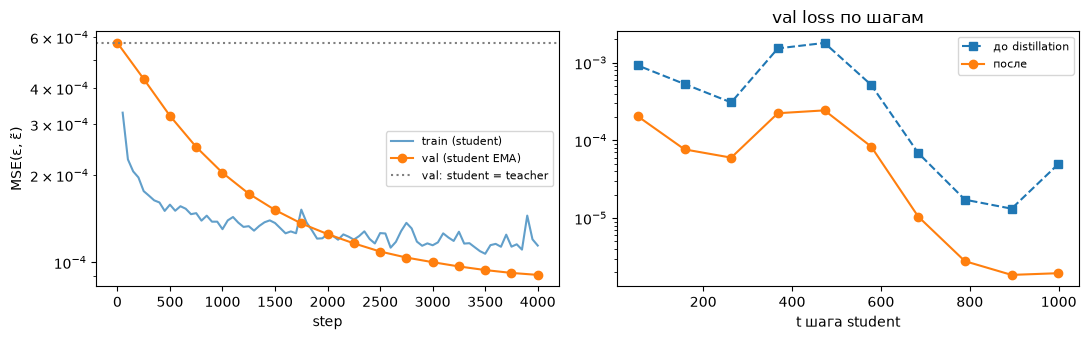

{'steps': 4000, 'seconds': 958.6, 'target_err': 0.00019613234551832336, 'val_init': 0.00057, 'val_final': 9e-05}


In [10]:
# Задание 9. Двухшаговые цели для distillation
# Progressive distillation (Salimans & Ho, 2022), один раунд TEACHER_STEPS → STUDENT_STEPS при том же w:
# x_t = q(x_t | x0) для реальной картинки; два guided DDIM-перехода замороженного teacher t → t_mid → s дают x_s*;
# цель student — такое ε̃, при котором один его DDIM-переход t → s попадает ровно в x_s*:
#   x_s = (α_s/α_t) x_t + (σ_s − α_s σ_t/α_t) ε  ⇒  ε̃ = (x_s* − (α_s/α_t) x_t) / (σ_s − α_s σ_t/α_t),
# при s = −1 (α=1, σ=0) это ε̃ = (x_t − α_t x_s*)/σ_t. Loss — MSE(ε_cfg_student, ε̃), student с той же CFG-формулой.
D_LR = 5e-5
D_WARMUP = 1 if FAST_DEV_RUN else 100
D_EMA = 0.999
D_CLIP = 1.0
D_LOG_EVERY = 1 if FAST_DEV_RUN else 50
D_VAL_EVERY = 1 if FAST_DEV_RUN else 250
D_CKPT_EVERY = 1 if FAST_DEV_RUN else 500
STUDENT_LAST = CKPT_DIR / 'student_last.pt'   # для возобновления после сбоя
STUDENT_PATH = ARTIFACTS / 'student.pt'
DISTILL_CONFIG = {'steps': DISTILL_STEPS, 'batch_size': DISTILL_BATCH, 'lr': D_LR, 'warmup': D_WARMUP,
                  'optimizer': 'AdamW(wd=0)', 'ema_decay': D_EMA, 'grad_clip': D_CLIP, 'guidance': GUIDANCE,
                  'teacher_steps': TEACHER_STEPS, 'student_steps': STUDENT_STEPS, 'loss': 'MSE(eps_student_cfg, eps_target)',
                  'k_sampling': 'uniform over student steps', 'seed': SEED, 'n_train': len(X_dtrain)}

# Коэффициенты переходов (t, t_mid, s) для каждого шага student k — в float64, затем на DEVICE
pair_t = torch.tensor([p[0] for p in DISTILL_PAIRS], device=DEVICE)
pair_m = torch.tensor([p[1] for p in DISTILL_PAIRS], device=DEVICE)
pair_ab = {name: torch.tensor([abar(p[i]) for p in DISTILL_PAIRS], dtype=torch.float64)
           for i, name in enumerate(['t', 'm', 's'])}
coef = {name: v.float().to(DEVICE) for name, v in {
    'a_t': pair_ab['t'].sqrt(), 's_t': (1 - pair_ab['t']).sqrt(),
    'a_m': pair_ab['m'].sqrt(), 's_m': (1 - pair_ab['m']).sqrt(),
    'a_s': pair_ab['s'].sqrt(), 's_s': (1 - pair_ab['s']).sqrt()}.items()}
denom = coef['s_s'] - coef['a_s'] * coef['s_t'] / coef['a_t']
assert bool((denom.abs() > 1e-3).all()), denom


def _c(name, k):
    return coef[name][k].view(-1, 1, 1, 1)


@torch.no_grad()
def distill_targets(x0, y, k, noise):
    """x_t из реальной картинки и цель ε̃ по двум guided DDIM-переходам замороженного teacher."""
    x_t = _c('a_t', k) * x0 + _c('s_t', k) * noise
    e1 = guided_eps(teacher, x_t, pair_t[k], y, GUIDANCE)
    x_m = _c('a_m', k) * (x_t - _c('s_t', k) * e1) / _c('a_t', k) + _c('s_m', k) * e1
    e2 = guided_eps(teacher, x_m, pair_m[k], y, GUIDANCE)
    x_s_target = _c('a_s', k) * (x_m - _c('s_m', k) * e2) / _c('a_m', k) + _c('s_s', k) * e2
    eps_target = (x_s_target - _c('a_s', k) / _c('a_t', k) * x_t) / denom[k].view(-1, 1, 1, 1)
    return x_t, x_s_target, eps_target


def distill_loss(net, x0, y, k, noise):
    """Поэлементный loss student на батче: (B,). Градиент идёт только в student."""
    x_t, _, eps_target = distill_targets(x0, y, k, noise)
    eps_student = guided_eps(net, x_t, pair_t[k], y, GUIDANCE)
    return (eps_student - eps_target).pow(2).mean((1, 2, 3))


# Проверка цели независимой реализацией (ddim_step из задания 3) на validation, по одному примеру на шаг k:
# два DDIM-шага teacher и один DDIM-шаг с ε̃ должны дать один и тот же x_s
with torch.no_grad():
    kk = torch.arange(STUDENT_STEPS, device=DEVICE)
    x0v, yv = X_dval[:STUDENT_STEPS].to(DEVICE), y_dval[:STUDENT_STEPS].to(DEVICE)
    nv = torch.randn(x0v.shape, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(SEED + 21))
    xt_v, xs_target_v, eps_target_v = distill_targets(x0v, yv, kk, nv)
    target_err = []
    for j, (t, m, s) in enumerate(DISTILL_PAIRS):
        xj, yj = xt_v[j:j + 1], yv[j:j + 1]
        xm, _ = ddim_step(xj, guided_eps(teacher, xj, pair_t[j:j + 1], yj, GUIDANCE), t, m)
        xs_two, _ = ddim_step(xm, guided_eps(teacher, xm, pair_m[j:j + 1], yj, GUIDANCE), m, s)
        xs_one, _ = ddim_step(xj, eps_target_v[j:j + 1], t, s)
        scale = xs_two.abs().max().item() + 1
        target_err.append(max((xs_one - xs_two).abs().max().item(), (xs_target_v[j:j + 1] - xs_two).abs().max().item()) / scale)
assert max(target_err) < 1e-3, target_err  # относительная ошибка float32

# --- Validation: фиксированные картинки, k и шум — сравнимы между шагами ---
val_k = torch.arange(len(X_dval), device=DEVICE) % STUDENT_STEPS
val_noise = torch.randn(X_dval.shape, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(SEED + 22))


@torch.no_grad()
def val_loss(net, batch=128):
    was_training = net.training; net.eval()
    per = torch.cat([distill_loss(net, X_dval[i:i + batch].to(DEVICE), y_dval[i:i + batch].to(DEVICE),
                                  val_k[i:i + batch], val_noise[i:i + batch]) for i in range(0, len(X_dval), batch)])
    net.train(was_training)
    per_k = [per[val_k == k].mean().item() for k in range(STUDENT_STEPS)]
    return per.mean().item(), per_k


init_val, init_val_per_k = val_loss(teacher)   # «student = teacher» до обучения — уровень, который надо улучшить

student_ema = copy.deepcopy(student).eval().requires_grad_(False)
d_opt = torch.optim.AdamW(student.parameters(), lr=D_LR, weight_decay=0.0)
d_sched = torch.optim.lr_scheduler.LambdaLR(d_opt, lambda s: min(1.0, (s + 1) / D_WARMUP))
batch_gen = torch.Generator().manual_seed(SEED + 30)                  # индексы картинок и k
noise_gen = torch.Generator(device=DEVICE).manual_seed(SEED + 31)     # шум x_t
d_history, d_val_history, d_start, d_seconds = [], [], 0, 0.0


def student_state(step):
    return {'run_tag': RUN_TAG, 'step': step, 'model': student.state_dict(), 'ema': student_ema.state_dict(),
            'optimizer': d_opt.state_dict(), 'lr_scheduler': d_sched.state_dict(), 'config': DISTILL_CONFIG,
            'teacher_sha256': TEACHER_SHA, 'history': d_history, 'val_history': d_val_history, 'seconds': d_seconds,
            'rng': {'batch_gen': batch_gen.get_state(), 'noise_gen': noise_gen.get_state()}}


if STUDENT_LAST.exists():
    st = torch.load(STUDENT_LAST, map_location='cpu', weights_only=False)
    assert st['run_tag'] == RUN_TAG and st['config'] == DISTILL_CONFIG and st['teacher_sha256'] == TEACHER_SHA, \
        'checkpoint student от другого режима, конфигурации или teacher'
    student.load_state_dict(st['model']); student_ema.load_state_dict(st['ema'])
    d_opt.load_state_dict(st['optimizer']); d_sched.load_state_dict(st['lr_scheduler'])
    batch_gen.set_state(st['rng']['batch_gen']); noise_gen.set_state(st['rng']['noise_gen'])
    d_history, d_val_history, d_start, d_seconds = st['history'], st['val_history'], st['step'], st['seconds']
    print(f'resume from step {d_start}')
if not d_val_history:
    d_val_history.append({'step': 0, 'val_loss': init_val, 'val_loss_per_k': init_val_per_k})

student.train()
acc_loss, acc_n = 0.0, 0
seconds_before, t_start = d_seconds, time.time()
for step in range(d_start + 1, DISTILL_STEPS + 1):
    idx = torch.randint(0, len(X_dtrain), (DISTILL_BATCH,), generator=batch_gen)
    k = torch.randint(0, STUDENT_STEPS, (DISTILL_BATCH,), generator=batch_gen).to(DEVICE)
    x0 = X_dtrain[idx].to(DEVICE); y = y_dtrain[idx].to(DEVICE)
    noise = torch.randn(x0.shape, device=DEVICE, generator=noise_gen)
    loss = distill_loss(student, x0, y, k, noise).mean()
    d_opt.zero_grad(set_to_none=True)
    loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(student.parameters(), D_CLIP)
    d_opt.step(); d_sched.step()
    with torch.no_grad():
        for pe, pm in zip(student_ema.parameters(), student.parameters()):
            pe.lerp_(pm, 1 - D_EMA)
    acc_loss += loss.item(); acc_n += 1
    if step % D_LOG_EVERY == 0 or step == DISTILL_STEPS:
        d_history.append({'step': step, 'loss': acc_loss / acc_n, 'lr': d_sched.get_last_lr()[0],
                          'grad_norm': float(grad_norm)})
        acc_loss, acc_n = 0.0, 0
    if step % D_VAL_EVERY == 0 or step == DISTILL_STEPS:
        v, v_k = val_loss(student_ema)
        d_val_history.append({'step': step, 'val_loss': v, 'val_loss_per_k': v_k})
        print({'step': step, 'train_loss': round(d_history[-1]['loss'], 5), 'val_loss_ema': round(v, 5),
               'init_val': round(init_val, 5)}, f'{seconds_before + time.time() - t_start:.0f}s')
    if step % D_CKPT_EVERY == 0 or step == DISTILL_STEPS:
        d_seconds = seconds_before + time.time() - t_start
        torch.save(student_state(step), STUDENT_LAST)

final_st = torch.load(STUDENT_LAST, map_location='cpu', weights_only=False)
assert final_st['step'] == DISTILL_STEPS
student.load_state_dict(final_st['model']); student_ema.load_state_dict(final_st['ema'])
d_history, d_val_history, d_seconds = final_st['history'], final_st['val_history'], final_st['seconds']
student_ema.eval()

# Teacher остался замороженным: веса бит-в-бит как в checkpoint lab 17
assert sum(p.double().sum().item() for p in teacher.parameters()) == TEACHER_FINGERPRINT
assert all(torch.equal(v.cpu(), ck['model'][k]) for k, v in teacher.state_dict().items()), 'teacher изменился'

final_val, final_val_per_k = d_val_history[-1]['val_loss'], d_val_history[-1]['val_loss_per_k']
torch.save({'run_tag': RUN_TAG, 'step': DISTILL_STEPS, 'model': student_ema.state_dict(), 'weights': 'ema',
            'model_config': ck['model_config'], 'student_dropout': 0.0, 'schedule': ck['schedule'],
            'null_class': NULL_CLASS, 'guidance': GUIDANCE, 'student_timesteps': STUDENT_TS,
            'teacher_timesteps': TEACHER_TS, 'teacher_sha256': TEACHER_SHA, 'config': DISTILL_CONFIG,
            'seconds': d_seconds, 'val_loss': final_val}, STUDENT_PATH)
with open(ARTIFACTS / 'distill_log.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(d_history[0].keys()))
    writer.writeheader(); writer.writerows(d_history)
distill_summary = {'run_tag': RUN_TAG, **DISTILL_CONFIG, 'seconds': d_seconds, 'checkpoint': str(STUDENT_PATH),
                   'resume_checkpoint': str(STUDENT_LAST), 'target_check_max_rel_err': max(target_err),
                   'val_loss_init_teacher': init_val, 'val_loss_final_student_ema': final_val,
                   'val_loss_per_k_init': init_val_per_k, 'val_loss_per_k_final': final_val_per_k,
                   'val_history': d_val_history, 'teacher_unchanged': True}
save_json('distill_summary.json', distill_summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([r['step'] for r in d_history], [r['loss'] for r in d_history], label='train (student)', alpha=0.7)
ax[0].plot([r['step'] for r in d_val_history], [r['val_loss'] for r in d_val_history], 'o-', label='val (student EMA)')
ax[0].axhline(init_val, color='gray', ls=':', label='val: student = teacher')
ax[0].set_yscale('log'); ax[0].set_xlabel('step'); ax[0].set_ylabel('MSE(ε, ε̃)'); ax[0].legend(fontsize=8)
ax[1].plot(STUDENT_TS, init_val_per_k, 's--', label='до distillation')
ax[1].plot(STUDENT_TS, final_val_per_k, 'o-', label='после')
ax[1].set_yscale('log'); ax[1].set_xlabel('t шага student'); ax[1].set_title('val loss по шагам'); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'distill_loss.png', dpi=120); plt.show()
print({'steps': DISTILL_STEPS, 'seconds': round(d_seconds, 1), 'target_err': max(target_err),
       'val_init': round(init_val, 5), 'val_final': round(final_val, 5)})

### Задание 10. Сравнение при равных и разных NFE

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните teacher 20/10 и student 10 на общих noise/labels; сохраните изображения и время.

**Результат.** Проверяемое состояние «Сравнение при равных и разных NFE» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните teacher 20/10 и student 10 на общих noise/labels; сохраните изображения и время» и его результат доступен следующему этапу.

**Сравнение teacher и student при равных и разных NFE**

- **Что делали**: на общем шуме, метках и w = 3 сгенерировали картинки тремя способами: teacher DDIM 20 (40 вызовов), teacher DDIM 10 и student DDIM 10 (по 20 вызовов, одна и та же сетка). Сравнили время, узнаваемость, разнообразие и отклонение от teacher 20 и от эталона DDIM 100. Добавили student на Pareto-график.
- **Зачем**: проверить, удалось ли student при вдвое меньшем бюджете приблизиться к teacher 20 и быть лучше teacher 10 при том же бюджете.
- **Результат**: comparison.csv, comparison.json, PNG трёх вариантов, teacher_vs_student.png, pareto_with_student.json/.png. Время: student 0.38 с, teacher 10 0.38 с, teacher 20 0.82 с. Узнаваемость у всех 1.00. Отклонение от teacher 20: student 0.032, teacher 10 0.061 — student вдвое ближе к цели. Разнообразие: student 0.271, teacher 20 0.272, teacher 10 0.258. Отклонение от эталона DDIM 100: student 0.082 — почти как teacher 20 (0.078) и как DPM-Solver++ 10 (0.082).

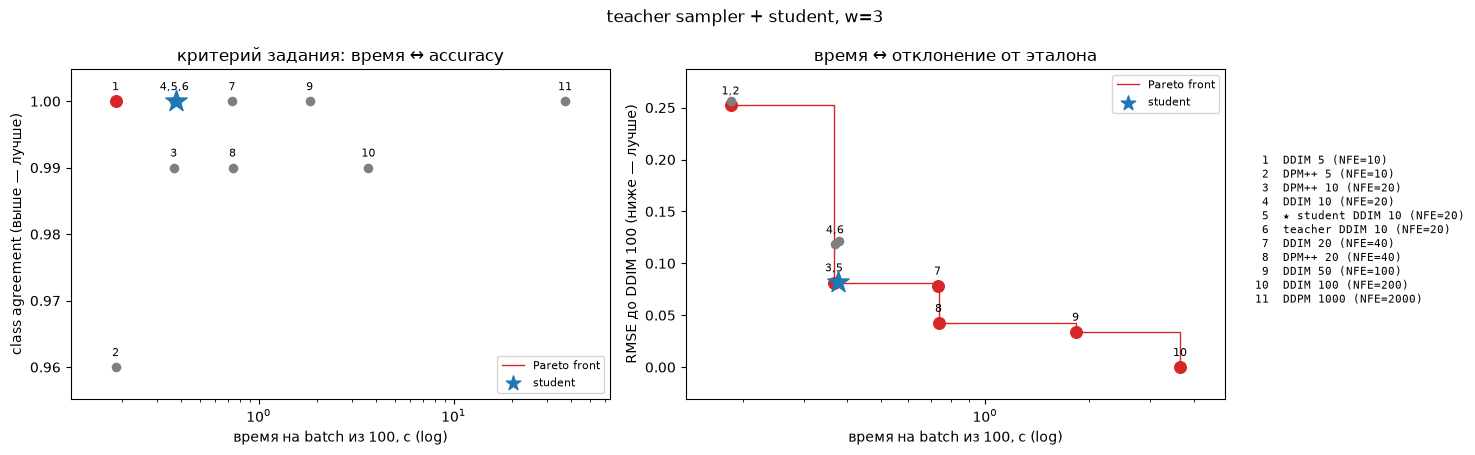

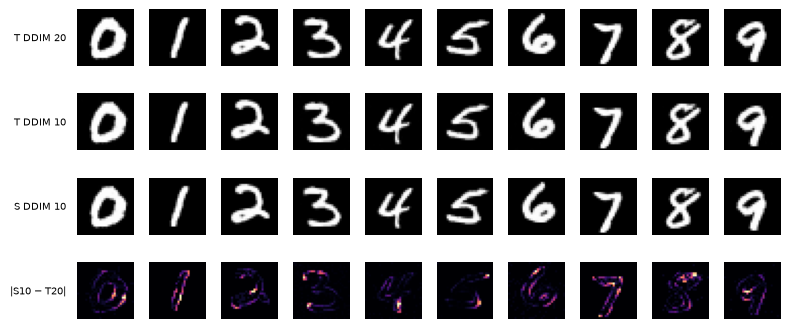

config              NFE    sec    acc  p(y|x)    div  rmse→T20  rmse→ref
teacher DDIM 20      40   0.81  1.000   1.000  0.272    0.0000    0.0785
teacher DDIM 10      20   0.38  1.000   1.000  0.258    0.0615    0.1218
student DDIM 10      20   0.38  1.000   1.000  0.271    0.0322    0.0820
Pareto (время, acc) с student: ['DDIM 5']
Pareto (время, RMSE до эталона) с student: ['DDIM 100', 'DDIM 50', 'DDIM 20', 'DDIM 5', 'DPM++ 20', 'DPM++ 10']


In [16]:
# Задание 10. Сравнение при равных и разных NFE
# Teacher 20 шагов (больше NFE), teacher 10 шагов (равный NFE) и student 10 шагов — одни и те же x_T, метки, w.
# Teacher 10 и student 10 идут по одной сетке STUDENT_TS = TEACHER_TS[::2]: отличаются только веса.
CMP_RUNS = [(f'teacher DDIM {TEACHER_STEPS}', teacher, TEACHER_TS),
            (f'teacher DDIM {STUDENT_STEPS}', teacher, STUDENT_TS),
            (f'student DDIM {STUDENT_STEPS}', student_ema, STUDENT_TS)]
cmp_rows = []
for name, net, ts in CMP_RUNS:
    row, x_png, probs = measure(name, 'DDIM', len(ts), net=net, timesteps=ts)
    row['model'] = 'student' if net is student_ema else 'teacher'
    cmp_rows.append(row); RESULTS[name] = {'x': x_png, 'probs': probs}

ref20 = RESULTS[f'teacher DDIM {TEACHER_STEPS}']['x']
for row in cmp_rows:
    x = RESULTS[row['name']]['x']
    row['rmse_to_teacher20'] = (x - ref20).pow(2).mean().sqrt().item()            # цель distillation
    row['rmse_to_ddim_ref'] = (x - RESULTS[REF_NAME]['x']).pow(2).mean().sqrt().item()
    row['per_sample_rmse_to_teacher20'] = (x - ref20).pow(2).mean((1, 2, 3)).sqrt().tolist()
t10, s10 = cmp_rows[1], cmp_rows[2]
assert t10['nfe_per_sample'] == s10['nfe_per_sample'], 'равный NFE'
assert cmp_rows[0]['nfe_per_sample'] == 2 * s10['nfe_per_sample'], 'teacher 20 тратит вдвое больше NFE'

comparison = {'guidance': GUIDANCE, 'n_samples': N_SAMPLES, 'teacher_grid': TEACHER_TS, 'student_grid': STUDENT_TS,
              'student_checkpoint': str(STUDENT_PATH), 'distill_steps': DISTILL_STEPS,
              'student_closer_to_teacher20_than_teacher10': s10['rmse_to_teacher20'] < t10['rmse_to_teacher20'],
              'rows': [{k: v for k, v in r.items() if k != 'per_sample_rmse_to_teacher20'} for r in cmp_rows]}
save_json('comparison.json', comparison)
flat_cmp = [k for k in cmp_rows[0] if k not in ('per_class_agreement', 'per_sample_rmse_to_teacher20')]
with open(ARTIFACTS / 'comparison.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=flat_cmp)
    writer.writeheader(); writer.writerows([{k: r[k] for k in flat_cmp} for r in cmp_rows])

# Pareto с учётом student: только измеренные точки (teacher-sampler из задания 6 + teacher 10 и student 10 на сетке student)
all_rows = budget_rows + [t10, s10]
front_all = pareto_front(all_rows, 'seconds', 'class_agreement')
# accuracy насыщена, поэтому второй критерий — близость к эталону DDIM 100 (меньше — лучше); DDPM стохастичен, без RMSE
ref_rows = [{**r, 'neg_rmse_ref': -r['rmse_to_ddim_ref']} for r in all_rows if not math.isnan(r['rmse_to_ddim_ref'])]
front_ref = pareto_front(ref_rows, 'seconds', 'neg_rmse_ref')
save_json('pareto_with_student.json', {'front_by_time': front_all,
                                       'front_by_nfe': pareto_front(all_rows, 'nfe_per_sample', 'class_agreement'),
                                       'front_by_time_rmse_ref': front_ref,
                                       'points': [{k: r[k] for k in ['name', 'nfe_per_sample', 'seconds', 'class_agreement',
                                                                     'rmse_to_ddim_ref']} for r in all_rows]})


import matplotlib.ticker

# Точки подписываются номерами (близкие точки — одной подписью «2,3»), расшифровка — списком справа от графиков
POINT_NUM = {r['name']: i + 1 for i, r in enumerate(sorted(all_rows, key=lambda r: (r['seconds'], r['name'])))}


def plot_with_student(ax, rows, y_key, ylabel, front):
    """Student — синяя звезда; точки фронта — красные; остальные — серые."""
    rows = [r for r in rows if not math.isnan(r[y_key])]
    y_range = (max(r[y_key] for r in rows) - min(r[y_key] for r in rows)) or 1.0
    clusters = []  # [x, y, [имена]] — точки, которые на графике почти совпадают
    for r in sorted(rows, key=lambda r: r['seconds']):
        is_student, on = r.get('model') == 'student', r['name'] in front
        ax.scatter(r['seconds'], r[y_key], marker='*' if is_student else 'o', s=260 if is_student else (70 if on else 35),
                   c='tab:blue' if is_student else ('tab:red' if on else 'tab:gray'), zorder=4 if is_student else 3)
        for cl in clusters:
            if abs(math.log10(cl[0] / r['seconds'])) < 0.06 and abs(cl[1] - r[y_key]) < 0.03 * y_range:
                cl[2].append(r['name']); break
        else:
            clusters.append([r['seconds'], r[y_key], [r['name']]])
    for x, y, names in clusters:
        ax.annotate(','.join(str(POINT_NUM[n]) for n in sorted(names, key=POINT_NUM.get)), (x, y), xytext=(0, 8),
                    textcoords='offset points', ha='center', fontsize=8)
    pts = sorted((r['seconds'], r[y_key]) for r in rows if r['name'] in front)
    ax.step([p[0] for p in pts], [p[1] for p in pts], where='post', c='tab:red', lw=1, label='Pareto front')
    ax.scatter([], [], marker='*', s=120, c='tab:blue', label='student')
    ax.set_xscale('log'); ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_xlabel(f'время на batch из {N_SAMPLES}, с (log)'); ax.set_ylabel(ylabel)
    ax.margins(x=0.1, y=0.12); ax.legend(fontsize=8, loc='lower right' if y_key == 'class_agreement' else 'upper right')


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_with_student(axes[0], all_rows, 'class_agreement', 'class agreement (выше — лучше)', front_all)
axes[0].set_title('критерий задания: время ↔ accuracy')
plot_with_student(axes[1], ref_rows, 'rmse_to_ddim_ref', f'RMSE до {REF_NAME} (ниже — лучше)', front_ref)
axes[1].set_title('время ↔ отклонение от эталона')
legend_text = '\n'.join(f"{POINT_NUM[r['name']]:>2}  {'★ ' if r.get('model') == 'student' else ''}{r['name']} (NFE={r['nfe_per_sample']:.0f})"
                        for r in sorted(all_rows, key=lambda r: POINT_NUM[r['name']]))
fig.suptitle(f'teacher sampler + student, w={GUIDANCE:g}')
fig.tight_layout(rect=(0, 0, 0.83, 1))
fig.text(0.84, 0.5, legend_text, va='center', fontsize=8, family='monospace')
fig.savefig(FIG_DIR / 'pareto_with_student.png', dpi=120); plt.show()

# Картинки: строки — конфигурации, столбцы — первый сэмпл каждого класса (общий x_T по столбцу) + |student − teacher20|
fig, axes = plt.subplots(4, 10, figsize=(8, 3.6))
panels = [(RESULTS[r['name']]['x'], r['name'].replace('teacher ', 'T ').replace('student ', 'S ')) for r in cmp_rows]
diff = (RESULTS[s10['name']]['x'] - ref20).abs()
for r, (x, name) in enumerate(panels + [(diff, '|S10 − T20|')]):
    for c in range(10):
        img = x[first_idx[c], 0]
        axes[r, c].imshow(img, cmap='magma' if r == 3 else 'gray', **({} if r == 3 else {'vmin': -1, 'vmax': 1}))
        axes[r, c].axis('off')
    axes[r, 0].text(-6, 14, name, ha='right', va='center', fontsize=7)
fig.tight_layout(); fig.savefig(FIG_DIR / 'teacher_vs_student.png', dpi=120); plt.show()

print(f"{'config':18s} {'NFE':>4} {'sec':>6} {'acc':>6} {'p(y|x)':>7} {'div':>6} {'rmse→T20':>9} {'rmse→ref':>9}")
for r in cmp_rows:
    print(f"{r['name']:18s} {r['nfe_per_sample']:>4.0f} {r['seconds']:>6.2f} {r['class_agreement']:>6.3f} "
          f"{r['mean_target_prob']:>7.3f} {r['within_class_diversity']:>6.3f} {r['rmse_to_teacher20']:>9.4f} "
          f"{r['rmse_to_ddim_ref']:>9.4f}")
print('Pareto (время, acc) с student:', front_all)
print('Pareto (время, RMSE до эталона) с student:', front_ref)

#### Пояснение к заданию 10: значение столбцов таблицы

Все строки получены на одном и том же начальном шуме $x_T$, с одними метками (по 10 картинок каждой цифры) и $w=3$. Различаются только модель и число шагов.

| Столбец | Что означает | Как читать |
|---|---|---|
| **config** | Модель и sampler: `teacher DDIM 20`, `teacher DDIM 10` или `student DDIM 10` | Teacher 10 и student 10 идут по одной сетке шагов, отличаются только веса |
| **NFE** | Число вызовов сети на одну картинку: шаги × 2 (ветви guidance с меткой и без) | Цена генерации: 40 у teacher 20, 20 у teacher 10 и student 10 |
| **sec** | Время генерации всего батча из 100 картинок на GPU, в секундах | Меньше — быстрее; растёт пропорционально NFE |
| **acc** | Class agreement: доля картинок, которые классификатор-судья из lab 17 распознал как запрошенную цифру | 1.0 — все цифры узнаны; у самого судьи точность на реальных цифрах 0.987 |
| **p(y\|x)** | Средняя уверенность судьи в нужной цифре | Ближе к 1 — цифры однозначнее |
| **div** | Внутриклассовое разнообразие: средняя попарная разница между картинками одной цифры (RMS пикселей в [0, 1]) | Больше — цифры разнообразнее; у реальных MNIST ≈ 0.31; падение означает «шаблонные» цифры |
| **rmse→T20** | Отклонение от результата teacher 20 при том же шуме (RMS пикселей в [−1, 1]) | Главная метрика distillation: насколько точно повторён учитель; у teacher 20 по определению 0 |
| **rmse→ref** | Отклонение от эталона DDIM 100 при том же шуме | Насколько траектория близка к «почти точной», полученной мелкими шагами; меньше — точнее |

**Как сравнивать.** При равном NFE (student 10 и teacher 10) student должен быть ближе к teacher 20 по `rmse→T20` и `rmse→ref` и не терять `div`. При разном NFE (student 10 и teacher 20) смотрим, насколько student приблизился к вдвое более дорогому варианту. `acc` почти всегда равен 1.0 и плохо различает варианты, поэтому основной вывод делается по `rmse→T20`, `rmse→ref` и `div`.


**Обучение одно и то же.** В lab 17 teacher учили одной задаче: дана картинка, зашумлённая до уровня $t$ (любого из 0…999), и номер $t$ — предскажи, какой шум добавлен. Ни DDPM, ни DDIM в обучении не участвуют. Это просто «угадыватель шума».

**DDPM и DDIM — это способы генерации (sampler), а не способы обучения.** Оба используют одну и ту же обученную сеть одинаково: «вот картинка, вот уровень $t$, скажи, какой тут шум». Различаются они только тем, что делают с ответом:

- **DDPM:** маленький шаг на один уровень вниз и свежий случайный шум;
- **DDIM:** большой шаг через несколько уровней и предсказанный шум вместо случайного.


### Задание 11 (дополнительное). Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

**Дополнительное мини-исследование: расположение шагов DDIM**

- **Что делали**: до запуска сформулировали гипотезу: квадратичная сетка (крупные шаги в начале, мелкие у чистой картинки) при том же числе вызовов сети приблизит DDIM к эталону DDIM 100. Меняли только расположение шагов; модель, шум, метки, w и судья те же. Сравнили равномерную и квадратичную сетки на 5 и 10 шагах.
- **Зачем**: проверить, можно ли бесплатно улучшить DDIM, переставив шаги, и где на траектории ошибка от крупных прыжков больше всего.
- **Результат**: bonus_spacing.json и bonus_spacing.png. Гипотеза опровергнута. Отклонение от эталона: 5 шагов — 0.252 у равномерной против 0.442 у квадратичной, 10 шагов — 0.118 против 0.209 (квадратичная хуже в 1.76–1.77 раза). При 5 шагах у квадратичной ниже и узнаваемость (0.98 против 1.00), и разнообразие (0.185 против 0.210). Причина: она экономит шаги в середине траектории, где, по заданию 9, ошибка самая большая.

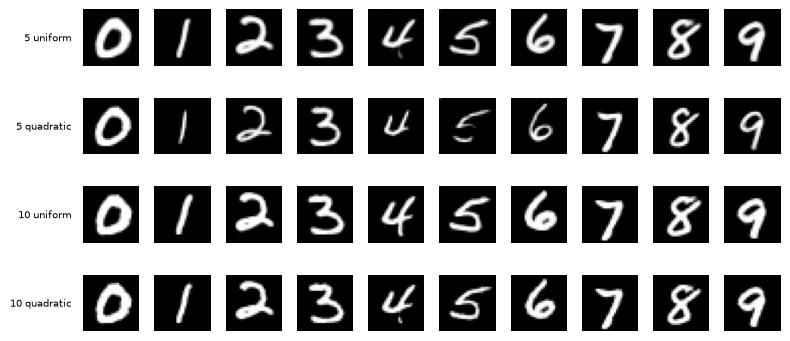

Сравнение сеток DDIM при одинаковом NFE (эталон — DDIM 100; teacher, x_T, метки и w=3 общие)

шагов | сетка         |  NFE |   acc | p(y|x) | разнообр. | серые пикс. | RMSE до эталона
-----------------------------------------------------------------------------------------
    5 | равномерная   |   10 |  1.00 |  1.000 |     0.210 |       0.114 |          0.2521
    5 | квадратичная  |   10 |  0.98 |  0.976 |     0.185 |       0.086 |          0.4424
        → RMSE: квадратичная хуже в 1.76 раза; acc 1.00 → 0.98; гипотеза НЕ подтверждается
-----------------------------------------------------------------------------------------
   10 | равномерная   |   20 |  1.00 |  1.000 |     0.255 |       0.096 |          0.1182
   10 | квадратичная  |   20 |  1.00 |  1.000 |     0.244 |       0.089 |          0.2087
        → RMSE: квадратичная хуже в 1.77 раза; acc 1.00 → 1.00; гипотеза НЕ подтверждается
-----------------------------------------------------------------------------------------

Ито

In [21]:
# Задание 11 (дополнительное). Творческое мини-исследование: сетка шагов DDIM
# Гипотеза (сформулирована до запуска): при малом бюджете шагов DDIM ошибка дискретизации ODE сосредоточена
# там, где быстро меняется x̂0 — при малых t (формирование штрихов). Квадратичная сетка t_i = (T−1)(1 − i/(n−1))²
# (DDIM, Song et al., 2021) ставит больше шагов при малых t и при том же NFE даст меньшую RMSE до эталона
# DDIM-ref и не ниже class agreement, а с ростом n разница исчезнет.
# Меняется один фактор — расположение шагов; teacher, x_T, метки, w, NFE и classifier те же; test не используется.
RUN_BONUS = True
BONUS_STEPS = [5, 10]


def make_timesteps_quadratic(n_steps, T=None):
    T = T_STEPS if T is None else T
    ts = np.round((T - 1) * np.linspace(1, 0, n_steps) ** 2).astype(int).tolist()
    assert all(a > b for a, b in zip(ts, ts[1:])) and ts[0] == T - 1 and ts[-1] == 0, ts
    return ts


if RUN_BONUS:
    bonus_rows = []
    for n in BONUS_STEPS:
        for spacing, ts in [('uniform', make_timesteps(n)), ('quadratic', make_timesteps_quadratic(n))]:
            name = f'DDIM {n} {spacing}'
            row, x_png, probs = measure(name, 'DDIM', n, timesteps=ts)
            row['spacing'], row['grid'] = spacing, ts
            row['rmse_to_ddim_ref'] = (x_png - RESULTS[REF_NAME]['x']).pow(2).mean().sqrt().item()
            RESULTS[name] = {'x': x_png, 'probs': probs}
            bonus_rows.append(row)
        pair = bonus_rows[-2:]
        assert pair[0]['nfe_per_sample'] == pair[1]['nfe_per_sample'], 'одинаковый бюджет NFE'
    keys = ['name', 'spacing', 'steps', 'nfe_per_sample', 'seconds', 'class_agreement', 'mean_target_prob',
            'within_class_diversity', 'gray_pixel_fraction', 'rmse_to_ddim_ref', 'grid']
    save_json('bonus_spacing.json', {'hypothesis': 'quadratic spacing → меньше RMSE до DDIM-ref при том же NFE',
                                     'fixed': 'teacher, x_T, labels, w, NFE, classifier', 'reference': REF_NAME,
                                     'rows': [{k: r[k] for k in keys} for r in bonus_rows]})

    fig, axes = plt.subplots(len(bonus_rows), 10, figsize=(8, 0.85 * len(bonus_rows) + 0.4))
    for r, row in enumerate(bonus_rows):
        for c in range(10):
            axes[r, c].imshow(RESULTS[row['name']]['x'][first_idx[c], 0], cmap='gray', vmin=-1, vmax=1)
            axes[r, c].axis('off')
        axes[r, 0].text(-6, 14, row['name'].replace('DDIM ', ''), ha='right', va='center', fontsize=7)
    fig.tight_layout(); fig.savefig(FIG_DIR / 'bonus_spacing.png', dpi=120); plt.show()

    # Итоговая таблица: пары «равномерная ↔ квадратичная» при одном NFE и вердикт по гипотезе
    print(f'Сравнение сеток DDIM при одинаковом NFE (эталон — {REF_NAME}; teacher, x_T, метки и w={GUIDANCE:g} общие)')
    print()
    header = f"{'шагов':>5} | {'сетка':<13} | {'NFE':>4} | {'acc':>5} | {'p(y|x)':>6} | {'разнообр.':>9} | {'серые пикс.':>11} | {'RMSE до эталона':>15}"
    print(header); print('-' * len(header))
    verdicts = []
    for n in BONUS_STEPS:
        pair = {r['spacing']: r for r in bonus_rows if r['steps'] == n}
        for spacing, label in [('uniform', 'равномерная'), ('quadratic', 'квадратичная')]:
            r = pair[spacing]
            print(f"{n:>5} | {label:<13} | {r['nfe_per_sample']:>4.0f} | {r['class_agreement']:>5.2f} | "
                  f"{r['mean_target_prob']:>6.3f} | {r['within_class_diversity']:>9.3f} | {r['gray_pixel_fraction']:>11.3f} | "
                  f"{r['rmse_to_ddim_ref']:>15.4f}")
        u, q = pair['uniform'], pair['quadratic']
        confirmed = q['rmse_to_ddim_ref'] < u['rmse_to_ddim_ref'] and q['class_agreement'] >= u['class_agreement']
        verdicts.append(confirmed)
        print(f"{'':>5}   → RMSE: квадратичная {'лучше' if q['rmse_to_ddim_ref'] < u['rmse_to_ddim_ref'] else 'хуже'} "
              f"в {max(q['rmse_to_ddim_ref'], u['rmse_to_ddim_ref']) / min(q['rmse_to_ddim_ref'], u['rmse_to_ddim_ref']):.2f} раза; "
              f"acc {u['class_agreement']:.2f} → {q['class_agreement']:.2f}; "
              f"гипотеза {'подтверждается' if confirmed else 'НЕ подтверждается'}")
        print('-' * len(header))
    print()
    print('Итог:', 'гипотеза подтверждена' if all(verdicts) else
          'гипотеза подтверждена частично' if any(verdicts) else 'гипотеза опровергнута',
          '(критерий: меньше RMSE до эталона и не ниже acc при том же NFE)')
    print()
    for r in bonus_rows:
        print(f"{r['name']:20s} сетка = {r['grid']}")

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

Сводная таблица (x_T seed 1842, 100 картинок, w=3, cuda); ориентиры: разнообразие реальных MNIST = 0.312, точность судьи на real test = 0.987
конфигурация     |   NFE | время, с |   acc | p(y|x) | разнообр. | серые | RMSE→DDIM100 | RMSE→T20
--------------------------------------------------------------------------------------------------
DDPM 1000        |  2000 |    37.30 |  1.00 |  1.000 |     0.289 | 0.088 |          nan |        —
DDIM 100         |   200 |     3.66 |  0.99 |  0.993 |     0.284 | 0.087 |       0.0000 |        —
DDIM 50          |   100 |     1.83 |  1.00 |  0.995 |     0.282 | 0.088 |       0.0341 |        —
DDIM 20          |    40 |     0.73 |  1.00 |  1.000 |     0.272 | 0.090 |       0.0785 |   0.0000
DDIM 10          |    20 |     0.37 |  1.00 |  1.000 |     0.255 | 0.096 |       0.1182 |        —
DDIM 5           |    10 |     0.18 |  1.00 |  1.000 |     0.210 | 0.114 |       0.2521 |        —
DPM++ 20         |    40 |     0.73 |  0.99 |  0.991 |     0.293 |

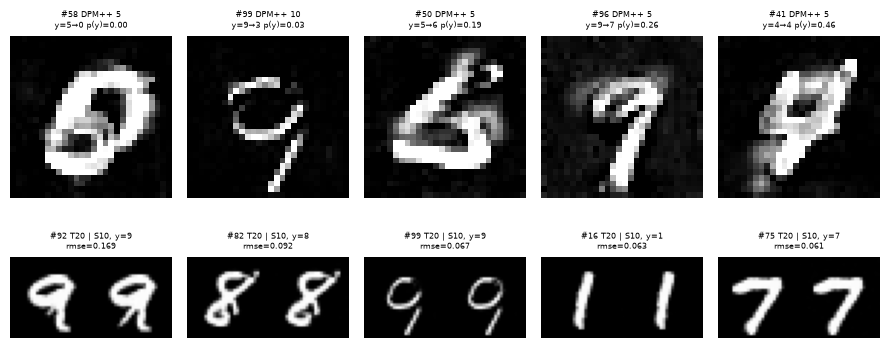

(а) Наименьшая уверенность судьи в нужной цифре:
  1. #58  DPM++ 5   цифра 5 → судья видит 0 (p(нужной)=0.001); тот же x_T узнан в 11 из 11 других конфигураций
  2. #99  DPM++ 10  цифра 9 → судья видит 3 (p(нужной)=0.033); тот же x_T узнан в 8 из 11 других конфигураций
       тоже неуверенно: {'DDIM 100': 0.32, 'DDIM 50': 0.53, 'DPM++ 20': 0.2, 'DPM++ 5': 0.05}
  3. #50  DPM++ 5   цифра 5 → судья видит 6 (p(нужной)=0.189); тот же x_T узнан в 11 из 11 других конфигураций
  4. #96  DPM++ 5   цифра 9 → судья видит 7 (p(нужной)=0.258); тот же x_T узнан в 11 из 11 других конфигураций
  5. #41  DPM++ 5   цифра 4 → судья видит 4 (p(нужной)=0.461); тот же x_T узнан в 11 из 11 других конфигураций

(б) Student дальше всего от teacher 20 (RMSE при общем x_T):
  1. #92  цифра 9: student 0.169, teacher 10 0.140 → student дальше; p(y): student 1.00, teacher 20 1.00
  2. #82  цифра 8: student 0.092, teacher 10 0.120 → student ближе; p(y): student 1.00, teacher 20 1.00
  3. #99  цифра 9: student 0.067

In [22]:
# Анализ результатов: сводная таблица измерений и неудачные примеры
# --- 1. Сводная таблица фактических измерений: общий x_T, метки, w=3, один batch из N_SAMPLES ---
summary_rows = budget_rows + [t10, s10]   # teacher DDIM 20 из задания 10 совпадает с «DDIM 20» (та же сетка)
ref20_rmse = {r['name']: r['rmse_to_teacher20'] for r in cmp_rows}
ref20_rmse['DDIM 20'] = 0.0
table_keys = ['name', 'nfe_per_sample', 'seconds', 'ms_per_sample', 'class_agreement', 'mean_target_prob',
              'within_class_diversity', 'gray_pixel_fraction', 'rmse_to_ddim_ref']
with open(ARTIFACTS / 'analysis_table.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=table_keys + ['rmse_to_teacher20'])
    writer.writeheader()
    writer.writerows([{**{k: r[k] for k in table_keys}, 'rmse_to_teacher20': ref20_rmse.get(r['name'], float('nan'))}
                      for r in summary_rows])

print(f'Сводная таблица (x_T seed {SAMPLE_SEED}, {N_SAMPLES} картинок, w={GUIDANCE:g}, {DEVICE}); '
      f'ориентиры: разнообразие реальных MNIST = {real_diversity:.3f}, точность судьи на real test = {cls_json["test_accuracy"]:.3f}')
header = (f"{'конфигурация':<16} | {'NFE':>5} | {'время, с':>8} | {'acc':>5} | {'p(y|x)':>6} | {'разнообр.':>9} | "
          f"{'серые':>5} | {'RMSE→DDIM100':>12} | {'RMSE→T20':>8}")
print(header); print('-' * len(header))
for r in summary_rows:
    r20 = ref20_rmse.get(r['name'])
    print(f"{r['name']:<16} | {r['nfe_per_sample']:>5.0f} | {r['seconds']:>8.2f} | {r['class_agreement']:>5.2f} | "
          f"{r['mean_target_prob']:>6.3f} | {r['within_class_diversity']:>9.3f} | {r['gray_pixel_fraction']:>5.3f} | "
          f"{r['rmse_to_ddim_ref']:>12.4f} | {'—' if r20 is None else f'{r20:.4f}':>8}")
print()

# --- 2. Неудачные примеры: (а) наименьшая p(y | x) среди всех конфигураций, без повторов одного x_T;
#        (б) сэмплы, где student сильнее всего отошёл от teacher 20 при общем x_T ---
N_WORST = 5
main_names = [r['name'] for r in budget_rows] + [r['name'] for r in cmp_rows]
cand = sorted((RESULTS[n]['probs'][k, sample_labels[k]].item(), n, k) for n in main_names for k in range(N_SAMPLES))
low_prob = []
for p_label, name, k in cand:
    if len(low_prob) == N_WORST:
        break
    if any(f['sample_index'] == k for f in low_prob):
        continue
    probs = RESULTS[name]['probs'][k]
    pred = int(probs.argmax())
    same_noise = {n: RESULTS[n]['probs'][k, sample_labels[k]].item() for n in main_names}
    low_prob.append({'kind': 'low p(label)', 'config': name, 'sample_index': k, 'label': int(sample_labels[k]),
                     'p_label': p_label, 'classifier_pred': pred, 'classifier_conf': probs[pred].item(),
                     'recognized_elsewhere': sum(v > 0.5 for n, v in same_noise.items() if n != name),
                     'p_label_same_noise': same_noise})

s_rmse = torch.tensor(s10['per_sample_rmse_to_teacher20'])
far = []
for k in s_rmse.topk(N_WORST).indices.tolist():
    far.append({'kind': 'student far from teacher20', 'sample_index': k, 'label': int(sample_labels[k]),
                'rmse_student_vs_teacher20': s_rmse[k].item(),
                'rmse_teacher10_vs_teacher20': t10['per_sample_rmse_to_teacher20'][k],
                'p_label_student': RESULTS[s10['name']]['probs'][k, sample_labels[k]].item(),
                'p_label_teacher20': RESULTS[cmp_rows[0]['name']]['probs'][k, sample_labels[k]].item()})

fig, axes = plt.subplots(2, N_WORST, figsize=(1.8 * N_WORST, 4.2))
for j, f in enumerate(low_prob):
    axes[0, j].imshow(RESULTS[f['config']]['x'][f['sample_index'], 0], cmap='gray', vmin=-1, vmax=1)
    axes[0, j].set_title(f"#{f['sample_index']} {f['config']}\ny={f['label']}→{f['classifier_pred']} p(y)={f['p_label']:.2f}",
                         fontsize=6)
for j, f in enumerate(far):
    k = f['sample_index']
    pair = torch.cat([RESULTS[cmp_rows[0]['name']]['x'][k, 0], RESULTS[s10['name']]['x'][k, 0]], 1)
    axes[1, j].imshow(pair, cmap='gray', vmin=-1, vmax=1)
    axes[1, j].set_title(f"#{k} T20 | S10, y={f['label']}\nrmse={f['rmse_student_vs_teacher20']:.3f}", fontsize=6)
for ax in axes.flat:
    ax.axis('off')
fig.tight_layout(); fig.savefig(FIG_DIR / 'failures.png', dpi=120); plt.show()

per_class_rows = {r['name']: r['per_class_agreement'] for r in budget_rows + cmp_rows}
save_json('failures.json', {'low_p_label': low_prob, 'student_far_from_teacher20': far,
                            'per_class_agreement': per_class_rows})

print('(а) Наименьшая уверенность судьи в нужной цифре:')
for i, f in enumerate(low_prob, 1):
    print(f"  {i}. #{f['sample_index']:<3} {f['config']:<9} цифра {f['label']} → судья видит {f['classifier_pred']} "
          f"(p(нужной)={f['p_label']:.3f}); тот же x_T узнан в {f['recognized_elsewhere']} из {len(main_names) - 1} других конфигураций")
    weak = {n: round(v, 2) for n, v in f['p_label_same_noise'].items() if v < 0.9 and n != f['config']}
    if weak:
        print(f"       тоже неуверенно: {weak}")
print()
print('(б) Student дальше всего от teacher 20 (RMSE при общем x_T):')
for i, f in enumerate(far, 1):
    better = 'ближе' if f['rmse_student_vs_teacher20'] < f['rmse_teacher10_vs_teacher20'] else 'дальше'
    print(f"  {i}. #{f['sample_index']:<3} цифра {f['label']}: student {f['rmse_student_vs_teacher20']:.3f}, "
          f"teacher 10 {f['rmse_teacher10_vs_teacher20']:.3f} → student {better}; p(y): student {f['p_label_student']:.2f}, "
          f"teacher 20 {f['p_label_teacher20']:.2f}")
print()
print('Классы с промахами (class agreement < 1):')
for name, pc in per_class_rows.items():
    misses = {c: round(a, 2) for c, a in enumerate(pc) if a < 1}
    if misses:
        print(f'  {name:<16} {misses}')

### Выводы по прогону

Числа ниже — из полного прогона (`FAST_DEV_RUN=False`, RTX 3060). Все конфигурации считались на одном и том же начальном шуме (seed 1842), с одними метками (по 10 картинок на цифру) и с $w=3$. Teacher — EMA-веса lab 17 (10 000 шагов), судья — классификатор lab 17 (точность 0.987 на 2000 картинок real test). Таблица воспроизводится ячейкой выше и сохраняется в `analysis_table.csv`.

#### 1. Таблица фактических метрик и времени

| конфигурация | NFE | время, с (batch 100) | acc | p(y\|x) | разнообразие | серые пиксели | RMSE → DDIM 100 | RMSE → teacher 20 |
|---|---|---|---|---|---|---|---|---|
| DDPM 1000 | 2000 | 37.30 | 1.00 | 1.000 | 0.289 | 0.088 | — (стохастичен) | — |
| DDIM 100 | 200 | 3.66 | 0.99 | 0.993 | 0.284 | 0.087 | 0 (эталон) | — |
| DDIM 50 | 100 | 1.83 | 1.00 | 0.995 | 0.282 | 0.088 | 0.034 | — |
| DDIM 20 = teacher 20 | 40 | 0.73 | 1.00 | 1.000 | 0.272 | 0.090 | 0.079 | 0 |
| DDIM 10 | 20 | 0.37 | 1.00 | 1.000 | 0.255 | 0.096 | 0.118 | — |
| DDIM 5 | 10 | 0.18 | 1.00 | 1.000 | 0.210 | 0.114 | 0.252 | — |
| DPM-Solver++ 20 | 40 | 0.73 | 0.99 | 0.991 | 0.293 | 0.078 | 0.043 | — |
| DPM-Solver++ 10 | 20 | 0.37 | 0.99 | 0.990 | 0.299 | 0.071 | 0.082 | — |
| DPM-Solver++ 5 | 10 | 0.18 | 0.96 | 0.950 | 0.293 | 0.182 | 0.256 | — |
| teacher DDIM 10 (сетка student) | 20 | 0.37 | 1.00 | 1.000 | 0.258 | 0.092 | 0.122 | 0.061 |
| **student DDIM 10** | 20 | 0.37 | 1.00 | 1.000 | 0.271 | 0.090 | 0.082 | **0.032** |

Ориентиры: разнообразие реальных цифр MNIST — 0.312. Distillation: 4000 шагов, 959 с; ошибка на отложенных картинках снизилась с 0.00057 (student = teacher) до 0.00009. Бонус (задание 11): квадратичная сетка DDIM даёт RMSE → DDIM 100 0.442 против 0.252 у равномерной при 5 шагах и 0.209 против 0.118 при 10 шагах.

#### 2. Неудачные примеры и их причины

Номер `#k` — индекс сэмпла в протоколе: цифра `k // 10`, свой начальный шум. Картинки — `figures/failures.png`.

1. **#58, DPM++ 5: цифра 5 → судья видит 0 (p(5) = 0.001).** Размытое кольцо с двойным контуром. Из того же шума все остальные 11 конфигураций рисуют узнаваемую 5. Значит, причина в sampler, а не в модели. При 5 шагах прыжки по ~250 шагов. Поправка второго порядка экстраполирует по разнице двух оценок $\hat x_0$, а первая из них (при t = 999, доля сигнала 0.006) очень грубая. Экстраполяция «перелетает» и склеивает штрихи в лишний контур.
2. **#50, DPM++ 5: 5 → 6 (p(5) = 0.19).** Тот же механизм: треугольная клякса с замкнутой нижней петлёй, которую судья принимает за 6. Остальные конфигурации на этом шуме рисуют 5 уверенно. Доля серых пикселей у DPM++ 5 — 0.182, вдвое больше, чем у остальных: остаётся недоочищенный шум.
3. **#96, DPM++ 5: 9 → 7 (p(9) = 0.26).** Петля девятки не замкнулась, по фону остался зернистый шум. Последний переход 250 → 0 → −1 слишком длинный, и поправка по прошлому шагу не успевает убрать шум. Без петли девятка похожа на 7.
4. **#41, DPM++ 5: 4 узнана, но неуверенно (p(4) = 0.46).** Толстая смазанная четвёрка с кляксой в центре. Это пограничный случай того же артефакта: форма угадана, штрихи нет.
5. **#99, DPM++ 10: 9 → 3 (p(9) = 0.03).** Это самый показательный случай, и причина здесь иная. Тонкая девятка с незамкнутой петлёй неуверенно распознаётся и у точных sampler: DDIM 100 — 0.32, DDIM 50 — 0.53, DPM++ 20 — 0.20. Зато «грубые» DDIM 10 и DDIM 5 рисуют уверенную девятку (1.00). Траектория, близкая к точной, ведёт к неоднозначной цифре. То есть это слабость самой модели teacher на этом шуме, а также судьи, обученного на типичных цифрах. Крупные шаги DDIM «усредняют» цифру до шаблонной и прячут эту слабость, что согласуется с падением разнообразия DDIM 10/5 (0.255/0.210).
6. **#92, student: 9 отклонился от teacher 20 сильнее всех (RMSE 0.169 против 0.140 у teacher 10).** Distillation в среднем вдвое сближает student с teacher 20 (0.032 против 0.061), но не для каждого сэмпла: в 2 из 5 худших случаев (#92, #99) student дальше от цели, чем необученный teacher 10. Ошибка student максимальна на шагах середины траектории (t ≈ 470–370, задание 9), где решается форма цифры. Поэтому расхождения проявляются в форме петель: у девятки появляется лишний штрих. Цифра при этом узнаётся (p = 1.0).

Все промахи судьи приходятся на классы 9 (с 4/7/3) и 5 (с 0/6). Это цифры с петлями, где незамкнутый или лишний штрих меняет класс.

#### 3. Ограничения

- **Малая выборка.** 100 картинок, по 10 на класс, и один набор начального шума. Одна ошибка — это 0.01 accuracy. Различия 0.99 против 1.00 статистически незначимы, доверительные интервалы не оценивались.
- **Accuracy насыщается.** Судья узнаёт почти все цифры даже при 10 NFE, поэтому фронт Pareto по критерию задания (время ↔ accuracy) вырождается в одну точку — DDIM 5. Качество при этом различается, что видно по разнообразию и RMSE.
- **Пиксельные метрики грубые.** Разнообразие (попарный RMS пикселей) завышается шумовыми артефактами: у DPM++ 5 оно 0.293 при худшем качестве. Метрик реализма (FID и подобных) нет.
- **Эталон — не истина.** DDIM 100 приближает решение той же ODE, а не «правильную» цифру. Близость к нему означает точность численного метода, а не качество картинки (пример #99).
- **Время замерено один раз на одной GPU.** Значения ~0.2–0.4 с чувствительны к шуму замера. Пропорциональность времени и NFE при этом устойчива.
- **Distillation ограничен.** Один раунд 20 → 10, один seed, только $w = 3$ и одна фиксированная сетка. Поведение student при других $w$ и сетках не проверялось.

#### 4. Проверяемые выводы

1. **Время пропорционально NFE.** DDPM 1000 (2000 NFE) — 37.3 с, DDIM 10 (20 NFE) — 0.37 с: отношение 100 при отношении NFE 100. Проверка: `seconds / nfe_per_sample` почти постоянно в `budgets.csv`.
2. **DDIM без переобучения сокращает NFE в 100 раз без потери узнаваемости:** acc = 1.00 у DDIM 10 и DDIM 5. Цена — разнообразие (0.284 → 0.255 → 0.210 при 100 → 10 → 5 шагах) и отклонение от эталона (0.034 → 0.118 → 0.252).
3. **При 10–20 шагах DPM-Solver++ точнее DDIM при том же NFE.** RMSE 0.082 против 0.118 (10 шагов), 0.043 против 0.079 (20 шагов), разнообразие 0.29–0.30 против 0.26–0.27. **При 5 шагах он хуже:** acc 0.96, серые пиксели 0.182 — экстраполяция второго порядка неустойчива на слишком длинных прыжках.
4. **Distillation работает.** При равном NFE (20) student вдвое ближе к teacher 20, чем teacher 10 (0.032 против 0.061), сохраняет разнообразие teacher 20 (0.271 против 0.272) и тратит вдвое меньше времени (0.37 против 0.73 с).
5. **Но на этом бюджете distillation не выигрывает у бесплатного solver.** По RMSE → DDIM 100 student (0.082) равен DPM++ 10 (0.082), которому обучение не нужно. Чтобы оправдать обучение, нужны дальнейшие раунды (10 → 5 → 2), где DPM++ уже деградирует.
6. **Квадратичная сетка на этой модели хуже равномерной** в 1.76–1.77 раза по RMSE (задание 11), потому что экономит шаги в середине траектории, где ошибка больше всего (задание 9).

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

In [23]:
# Сводка для сдачи: версии, конфигурация, таблица измерений, артефакты
import sys, platform
import matplotlib, torchvision, PIL

# Сводка прогона: версии, источники/лицензии, конфигурация, таблица фактических измерений, список артефактов
run_info = {
    'run_tag': RUN_TAG, 'fast_dev_run': FAST_DEV_RUN, 'seed': SEED, 'device': DEVICE,
    'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
    'versions': {'python': sys.version.split()[0], 'platform': platform.platform(), 'torch': torch.__version__,
                 'torchvision': torchvision.__version__, 'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
                 'pillow': PIL.__version__},
    'data': {'name': 'MNIST', 'source': 'torchvision.datasets.MNIST', 'license': 'CC BY-SA 3.0',
             'distill_train': f'train [0, {N_TRAIN})', 'distill_val': f'train [{int(dval_idx[0])}, {int(dval_idx[-1]) + 1})',
             'classifier_check': f'test, {len(test_idx)} images (lab 17 split)'},
    'models': {'teacher': f'TinyDenoiser lab 17, {ck["step"]} steps, EMA, sha256 {TEACHER_SHA[:16]}',
               'classifier': 'DigitClassifier lab 17', 'student': f'TinyDenoiser, init = teacher, {DISTILL_STEPS} distill steps'},
    'config': {'T': T_STEPS, 'guidance': GUIDANCE, 'samples_per_class': SAMPLES_PER_CLASS, 'ddim_steps': DDIM_STEPS,
               'dpm_steps': DPM_STEPS, 'teacher_grid': TEACHER_TS, 'student_grid': STUDENT_TS, 'distill': DISTILL_CONFIG},
    'timing_seconds': {'distillation': d_seconds, 'notebook_total': time.time() - NOTEBOOK_T0},
    'classifier_test_accuracy': cls_json['test_accuracy'],
}
save_json('run_info.json', run_info)

for required in (ARTIFACTS / 'teacher_check.json', ARTIFACTS / 'protocol.json', ARTIFACTS / 'budgets.csv',
                 ARTIFACTS / 'pareto.json', STUDENT_PATH, ARTIFACTS / 'comparison.csv', ARTIFACTS / 'failures.json'):
    assert required.exists(), f'нет {required}'

print(json.dumps(run_info['versions'], indent=1))
print(f"\nclassifier test acc {cls_json['test_accuracy']:.4f}; distillation {DISTILL_STEPS} шагов, {d_seconds / 60:.1f} мин")
print(f"{'config':18s} {'NFE':>5} {'sec':>7} {'acc':>6} {'p(y|x)':>7} {'div':>6}")
for r in budget_rows + cmp_rows:
    print(f"{r['name']:18s} {r['nfe_per_sample']:>5.0f} {r['seconds']:>7.2f} {r['class_agreement']:>6.3f} "
          f"{r['mean_target_prob']:>7.3f} {r['within_class_diversity']:>6.3f}")
print('\nartifacts:')
for p in sorted(ARTIFACTS.rglob('*')):
    if p.is_file():
        print(f'  {p.relative_to(ARTIFACTS)}  ({p.stat().st_size / 1024:.0f} KB)')

{
 "python": "3.12.1",
 "platform": "Windows-11-10.0.22631-SP0",
 "torch": "2.11.0+cu128",
 "torchvision": "0.26.0+cu128",
 "numpy": "2.5.3",
 "matplotlib": "3.11.2",
 "pillow": "12.3.0"
}

classifier test acc 0.9870; distillation 4000 шагов, 16.0 мин
config               NFE     sec    acc  p(y|x)    div
DDPM 1000           2000   37.30  1.000   1.000  0.289
DDIM 100             200    3.66  0.990   0.993  0.284
DDIM 50              100    1.83  1.000   0.995  0.282
DDIM 20               40    0.73  1.000   1.000  0.272
DDIM 10               20    0.37  1.000   1.000  0.255
DDIM 5                10    0.18  1.000   1.000  0.210
DPM++ 20              40    0.73  0.990   0.991  0.293
DPM++ 10              20    0.37  0.990   0.990  0.299
DPM++ 5               10    0.18  0.960   0.950  0.293
teacher DDIM 20       40    0.81  1.000   1.000  0.272
teacher DDIM 10       20    0.38  1.000   1.000  0.258
student DDIM 10       20    0.38  1.000   1.000  0.271

artifacts:
  analysis_table.csv 